In [ ]:
from get_data.get_data import get_competitions

get_competitions()

In [ ]:
from get_data.get_data import get_matches

get_matches(55, 43)

* passes - podania
* carrys - prowadzenie piłki
* ball_receipts - odbiory piłki
* duels - pojedynki
* dribbles - drybling
* blocks - zablokowanie piłki
* clearances - wybicie piłki
* dispossesseds - przechwyt piłki
* errors - błędy
* foul_committeds - popełniony faul
* foul_wons - foul przeciwnika
* half_ends - koniec połowy
* injury_stoppages - przerwa kontuzyjna
* interceptions - przechwyt
* miscontrols - nieopanowanie piłki
* shots - strzały

In [1]:
from get_data.get_data import get_merged_events

MATCH_ID = 3788776

EVENTS_TO_ANALIZE = ['passes', 'carrys', 'ball_receipts', 'ball_recoverys', 'duels', 'dribbles', 'blocks', 'clearances', 
'dispossesseds', 'errors', 'foul_committeds', 'foul_wons', 'half_ends', 'injury_stoppages', 'interceptions', 'miscontrols', 'shots']

merged_events = get_merged_events(EVENTS_TO_ANALIZE, MATCH_ID)


In [2]:
from grid_areas.grid_areas import get_event_area

def add_areas_and_pos_merged_events(eventDataFrame, areas_x = 12, areas_y = 8):
    event_start_locations = [[value[0], value[1]] if value != '' else '' for value in eventDataFrame['location'].values]
    event_end_locations = [[value['end_location'][0], value['end_location'][1]] if value != '' and 'end_location' in value.keys() else '' for value in eventDataFrame['event'].values]

    event_start_areas = [get_event_area(location, areas_x, areas_y) if location != '' else '' for location in event_start_locations]
    event_end_areas = [get_event_area(location, areas_x, areas_y) if location != '' else '' for location in event_end_locations]

    event_area_codes = [f'{a}{b}' for a,b in zip(event_start_areas, event_end_areas)]
    newEventDataFrame = eventDataFrame

    newEventDataFrame['start_x'] = [value[0] if value != '' else '' for value in event_start_locations]
    newEventDataFrame['start_y'] = [value[1] if value != '' else '' for value in event_start_locations]

    newEventDataFrame['end_x'] = [value[0] if value != '' else '' for value in event_end_locations]
    newEventDataFrame['end_y'] = [value[1] if value != '' else '' for value in event_end_locations]

    newEventDataFrame['start_area'] = event_start_areas
    newEventDataFrame['end_area'] = event_end_areas
    newEventDataFrame['area_code'] = event_area_codes

    return newEventDataFrame

In [3]:
merged_events = add_areas_and_pos_merged_events(merged_events)

In [4]:
from sequences.get_sequences import get_event_sequences

sequences = get_event_sequences(merged_events)

In [14]:
import matplotlib.pyplot as plt
from matplotlib.patches import Arc

def draw_pitch(ax, areas_x, areas_y, scale=1):
    # size of the pitch is 120, 80
    
    X = ['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P','Q','R','S','T']
    Y = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20]

    #Pitch Outline & Centre Line
    plt.plot([0,0],[0,80*scale], color="black")
    plt.plot([0,120*scale],[80*scale,80*scale], color="black")
    plt.plot([120*scale,120*scale],[80*scale,0], color="black")
    plt.plot([120*scale,0],[0,0], color="black")
    plt.plot([60*scale,60*scale],[0,80*scale], color="black")
    
    for i in range (0,areas_x):
        plt.text((((60/areas_x)+i*120/areas_x)-1)*scale, 82*scale, X[i], fontdict=None, fontsize = 8*scale)
        
    for i in range (0,areas_y):
        plt.text(-3*scale, (((40/areas_y)+i*80/areas_y)-1)*scale, Y[i], fontdict=None, fontsize = 8*scale)

    #Left Penalty Area
    plt.plot([14.6*scale,14.6*scale],[57.8*scale,22.2*scale],color="black")
    plt.plot([0,14.6*scale],[57.8*scale,57.8*scale],color="black")
    plt.plot([0,14.6*scale],[22.2*scale,22.2*scale],color="black")

    #Right Penalty Area
    plt.plot([120*scale,105.4*scale],[57.8*scale,57.8*scale],color="black")
    plt.plot([105.4*scale,105.4*scale],[57.8*scale,22.5*scale],color="black")
    plt.plot([120*scale, 105.4*scale],[22.5*scale,22.5*scale],color="black")

    #Left 6-yard Box
    plt.plot([0,4.9*scale],[48*scale,48*scale],color="black")
    plt.plot([4.9*scale,4.9*scale],[48*scale,32*scale],color="black")
    plt.plot([0,4.9*scale],[32*scale,32*scale],color="black")

    #Right 6-yard Box
    plt.plot([120*scale,115.1*scale],[48*scale,48*scale],color="black")
    plt.plot([115.1*scale,115.1*scale],[48*scale,32*scale],color="black")
    plt.plot([120*scale,115.1*scale],[32*scale,32*scale],color="black")
    
    #Sectors
    for i in range(1, areas_y):
        plt.plot([120*scale,0],[(80/areas_y)*i*scale,(80/areas_y)*i*scale], color="gray")

    for i in range(1, areas_x):
        plt.plot([(120/areas_x)*i*scale,(120/areas_x)*i*scale],[80*scale,0], color="gray")
    
    #Prepare Circles
    centreCircle = plt.Circle((60*scale,40*scale),8.1*scale,color="black",fill=False)
    centreSpot = plt.Circle((60*scale,40*scale),0.71,color="black")
    leftPenSpot = plt.Circle((9.7*scale,40*scale),0.71,color="black")
    rightPenSpot = plt.Circle((110.3*scale,40*scale),0.71,color="black")

    #Draw Circles
    ax.add_patch(centreCircle)
    ax.add_patch(centreSpot)
    ax.add_patch(leftPenSpot)
    ax.add_patch(rightPenSpot)

def draw_events_sequence2(sequence, start_team, areas_x, areas_y, scale):
    if areas_x < 2:
        areas_x = 2
    if areas_y < 2:
        areas_y = 2
    if scale < 1:
        scale = 1

    fig, ax = plt.subplots()
    fig.set_size_inches(7*scale, 5*scale)
    i = 0
    team = [team for team in sequence['possession_team']][0]
    player = ''
    
    print(f'Team: {team}')

    for index, row in sequence.iterrows():
        if player != row['player']:
            player = row['player']
            i+=1
        
        type = row['type']
        timespamp = row['timestamp']
            
        print(f'{i}: {player} ({type}) <{timespamp}>')

        if row['possession_team'] == start_team and row['team'] == start_team:
            general_color = 'blue'
        else:
            general_color = 'red'

        match row['type']:
            case 'Ball Receipt*':
                plt.plot(int(row['start_x']*scale), int(row['start_y']*scale), marker='.',
                markersize=32, markeredgecolor=general_color, markerfacecolor=general_color)
                plt.plot(int(row['start_x']*scale), int(row['start_y']*scale), marker='o',
                markersize=32, markeredgecolor=general_color, markerfacecolor="black")
            case 'Duel':
                plt.plot(int(row['start_x']*scale), int(row['start_y']*scale), marker='v',
                markersize=32, markeredgecolor=general_color, markerfacecolor=general_color)
            case 'Pass':
                plt.plot([int(row['start_x']*scale), int(row['end_x']*scale)],
                [int(row['start_y']*scale),int(row['end_y']*scale)], color=general_color, linewidth=4.0)
                plt.plot(int(row['start_x']*scale), int(row['start_y']*scale), marker='o',
                markersize=32, markeredgecolor=general_color, markerfacecolor="black")
            case 'Carry':
                plt.plot([int(row['start_x']*scale), int(row['end_x']*scale)],
                [int(row['start_y']*scale),int(row['end_y']*scale)], color='green', linewidth=4.0)
            case 'Dispossessed':
                plt.plot(int(row['start_x']*scale), int(row['start_y']*scale), marker='s',
                markersize=32, markeredgecolor=general_color, markerfacecolor=general_color)
            case _:
                plt.plot(int(row['start_x']*scale), int(row['start_y']*scale), marker='1',
                markersize=32, markeredgecolor=general_color, markerfacecolor="black")
            
        plt.text(int(row['start_x']*scale)-2, int(row['start_y']*scale)-2, str(i),
        color='white', fontsize=16)

    draw_pitch(ax, areas_x, areas_y, scale)
    plt.show()

Sequence: 1
Team: Sweden
1: Sebastian Larsson (Pass) <00:00:00.080>
2: Victor Nilsson Lindelöf (Ball Receipt*) <00:00:01.502>
2: Victor Nilsson Lindelöf (Carry) <00:00:01.502>
2: Victor Nilsson Lindelöf (Pass) <00:00:02.653>
3: Mikael Lustig (Ball Receipt*) <00:00:05.863>
3: Mikael Lustig (Pass) <00:00:05.863>
4: Robin Quaison (Ball Receipt*) <00:00:09.353>
4: Robin Quaison (Duel) <00:00:09.353>


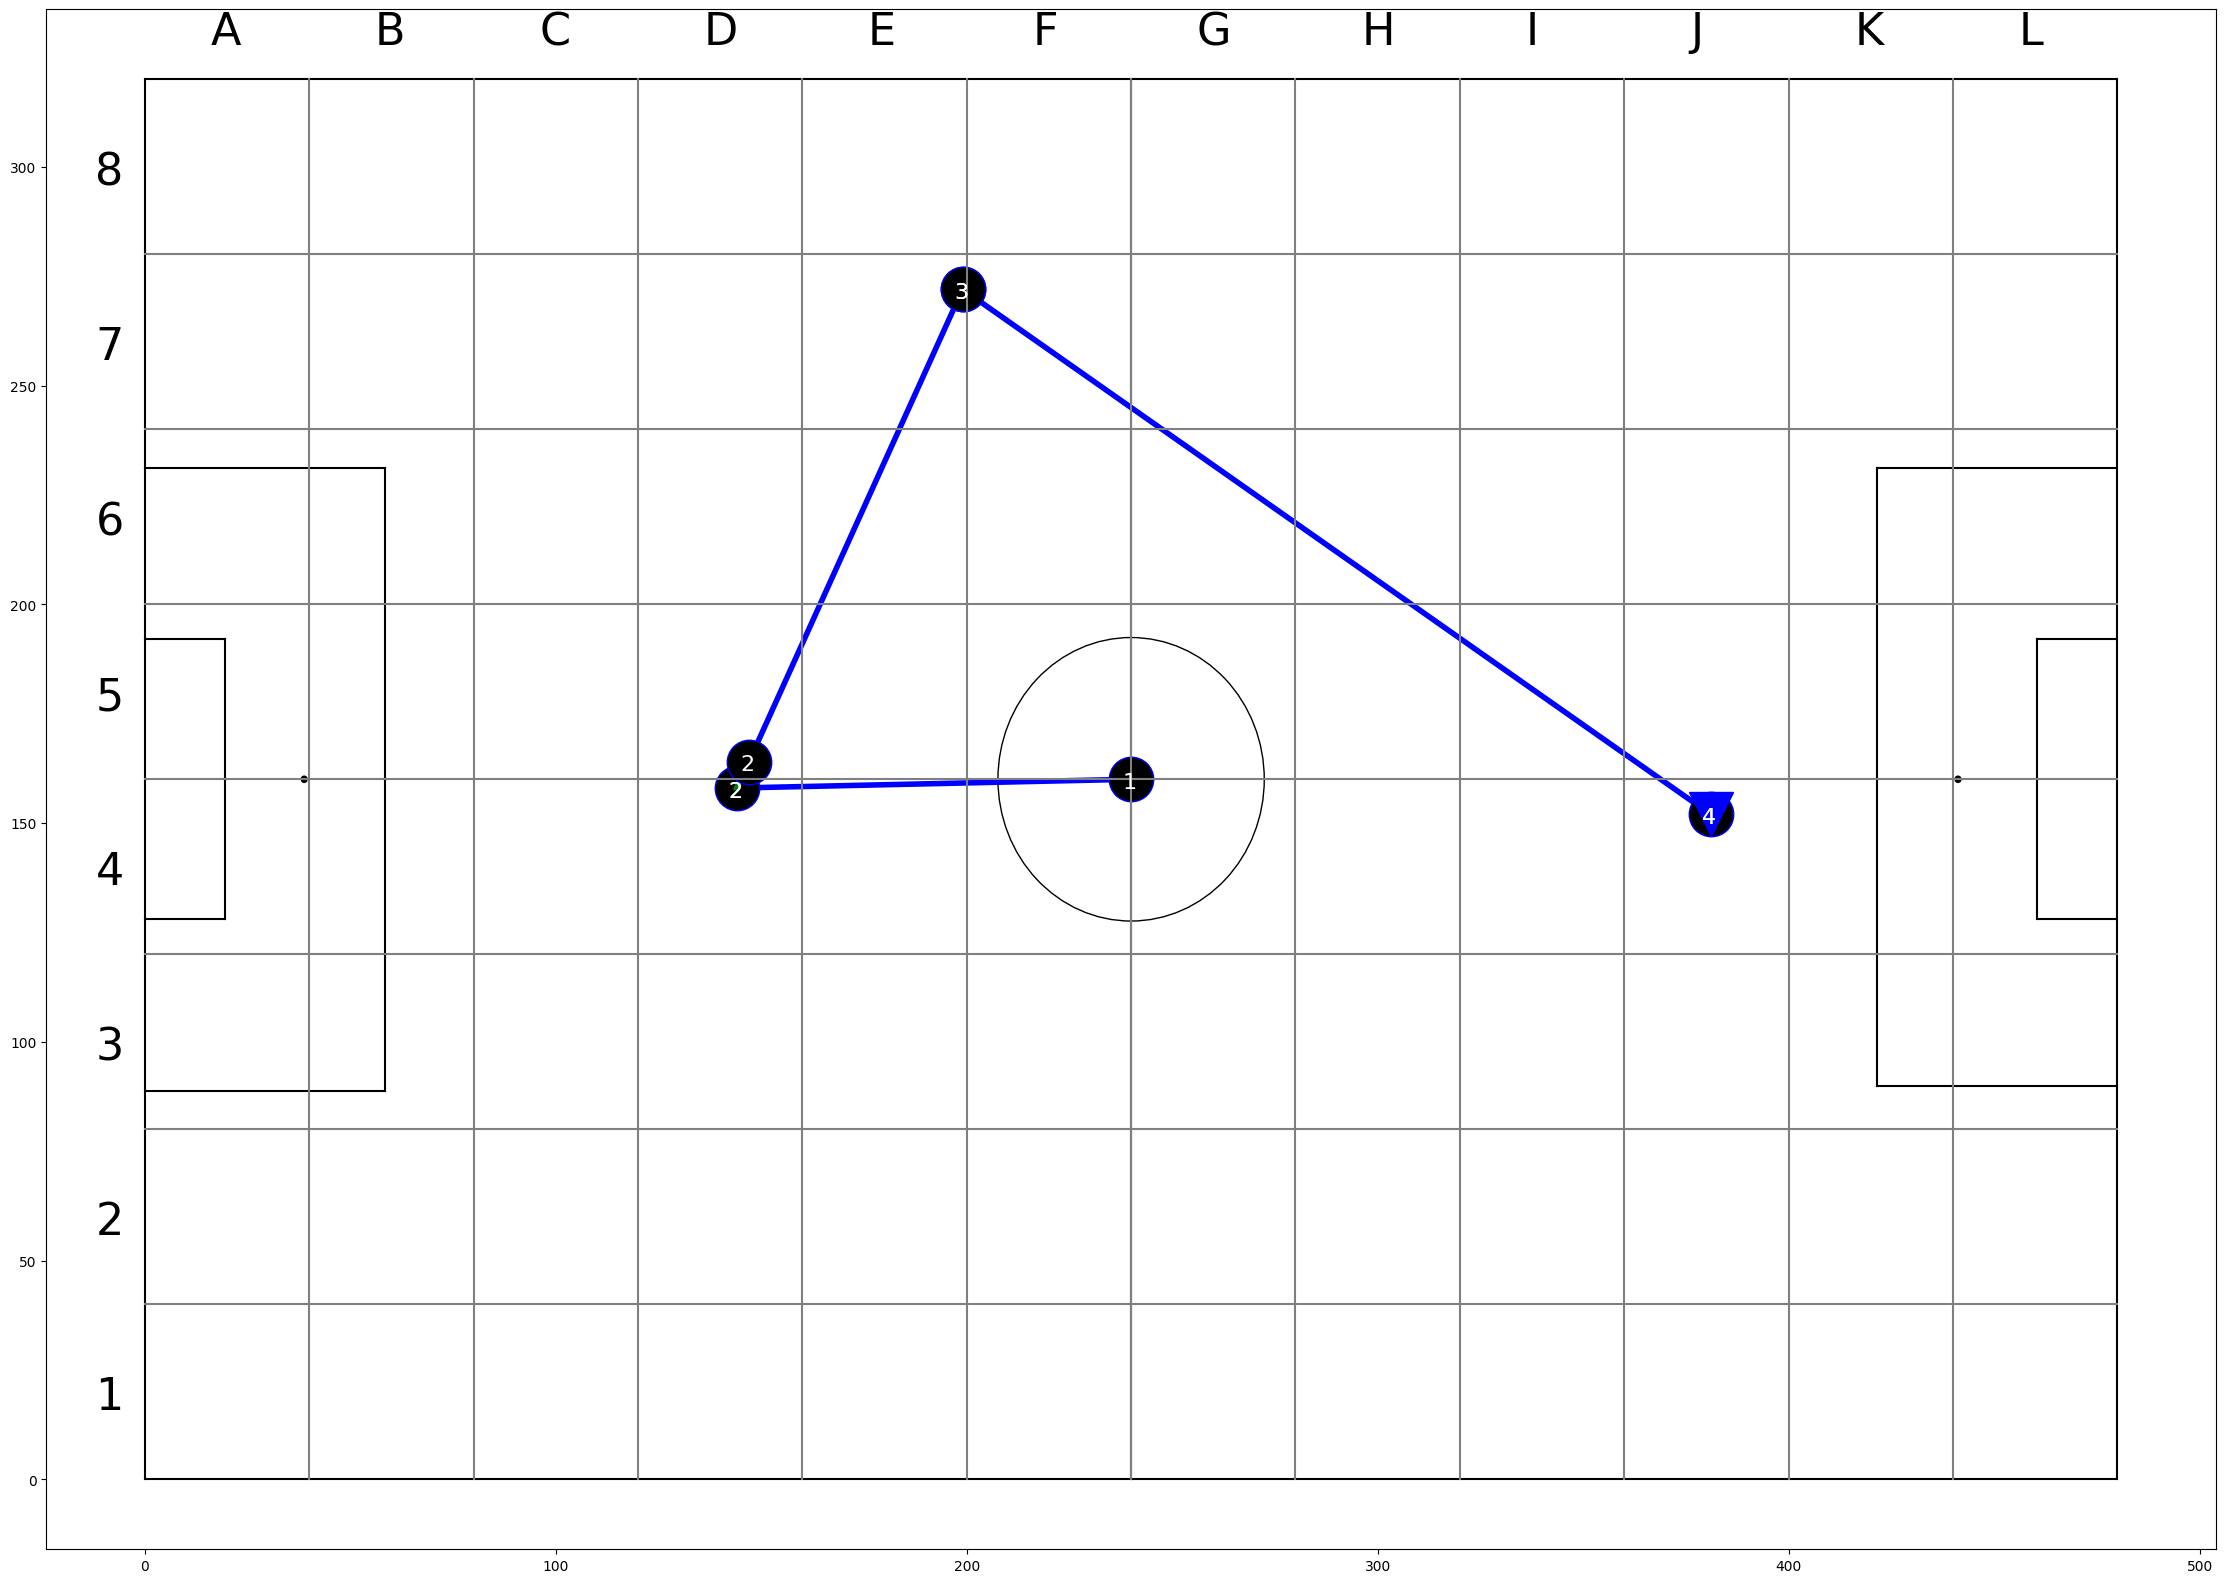

Sequence: 2
Team: Poland
1: Kamil Glik (Pass) <00:00:09.353>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:00:10.310>
2: Mateusz Andrzej Klich (Pass) <00:00:10.344>
3: Piotr Zieliński (Ball Receipt*) <00:00:11.479>
3: Piotr Zieliński (Carry) <00:00:11.479>
3: Piotr Zieliński (Pass) <00:00:13.421>
4: Robert Lewandowski (Ball Receipt*) <00:00:14.364>
4: Robert Lewandowski (Carry) <00:00:14.364>
4: Robert Lewandowski (Pass) <00:00:15.523>
5: Tymoteusz Puchacz (Ball Receipt*) <00:00:16.740>
5: Tymoteusz Puchacz (Carry) <00:00:16.740>
5: Tymoteusz Puchacz (Pass) <00:00:17.456>
6: Jan Bednarek (Ball Receipt*) <00:00:18.427>
6: Jan Bednarek (Carry) <00:00:18.427>
6: Jan Bednarek (Pass) <00:00:19.747>
7: Bartosz Bereszyński (Ball Receipt*) <00:00:21.153>
7: Bartosz Bereszyński (Carry) <00:00:21.153>
7: Bartosz Bereszyński (Pass) <00:00:25.168>
8: Kamil Glik (Ball Receipt*) <00:00:26.550>
8: Kamil Glik (Carry) <00:00:26.550>
8: Kamil Glik (Pass) <00:00:27.497>
9: Jan Bednarek (Ball Receipt*) <00

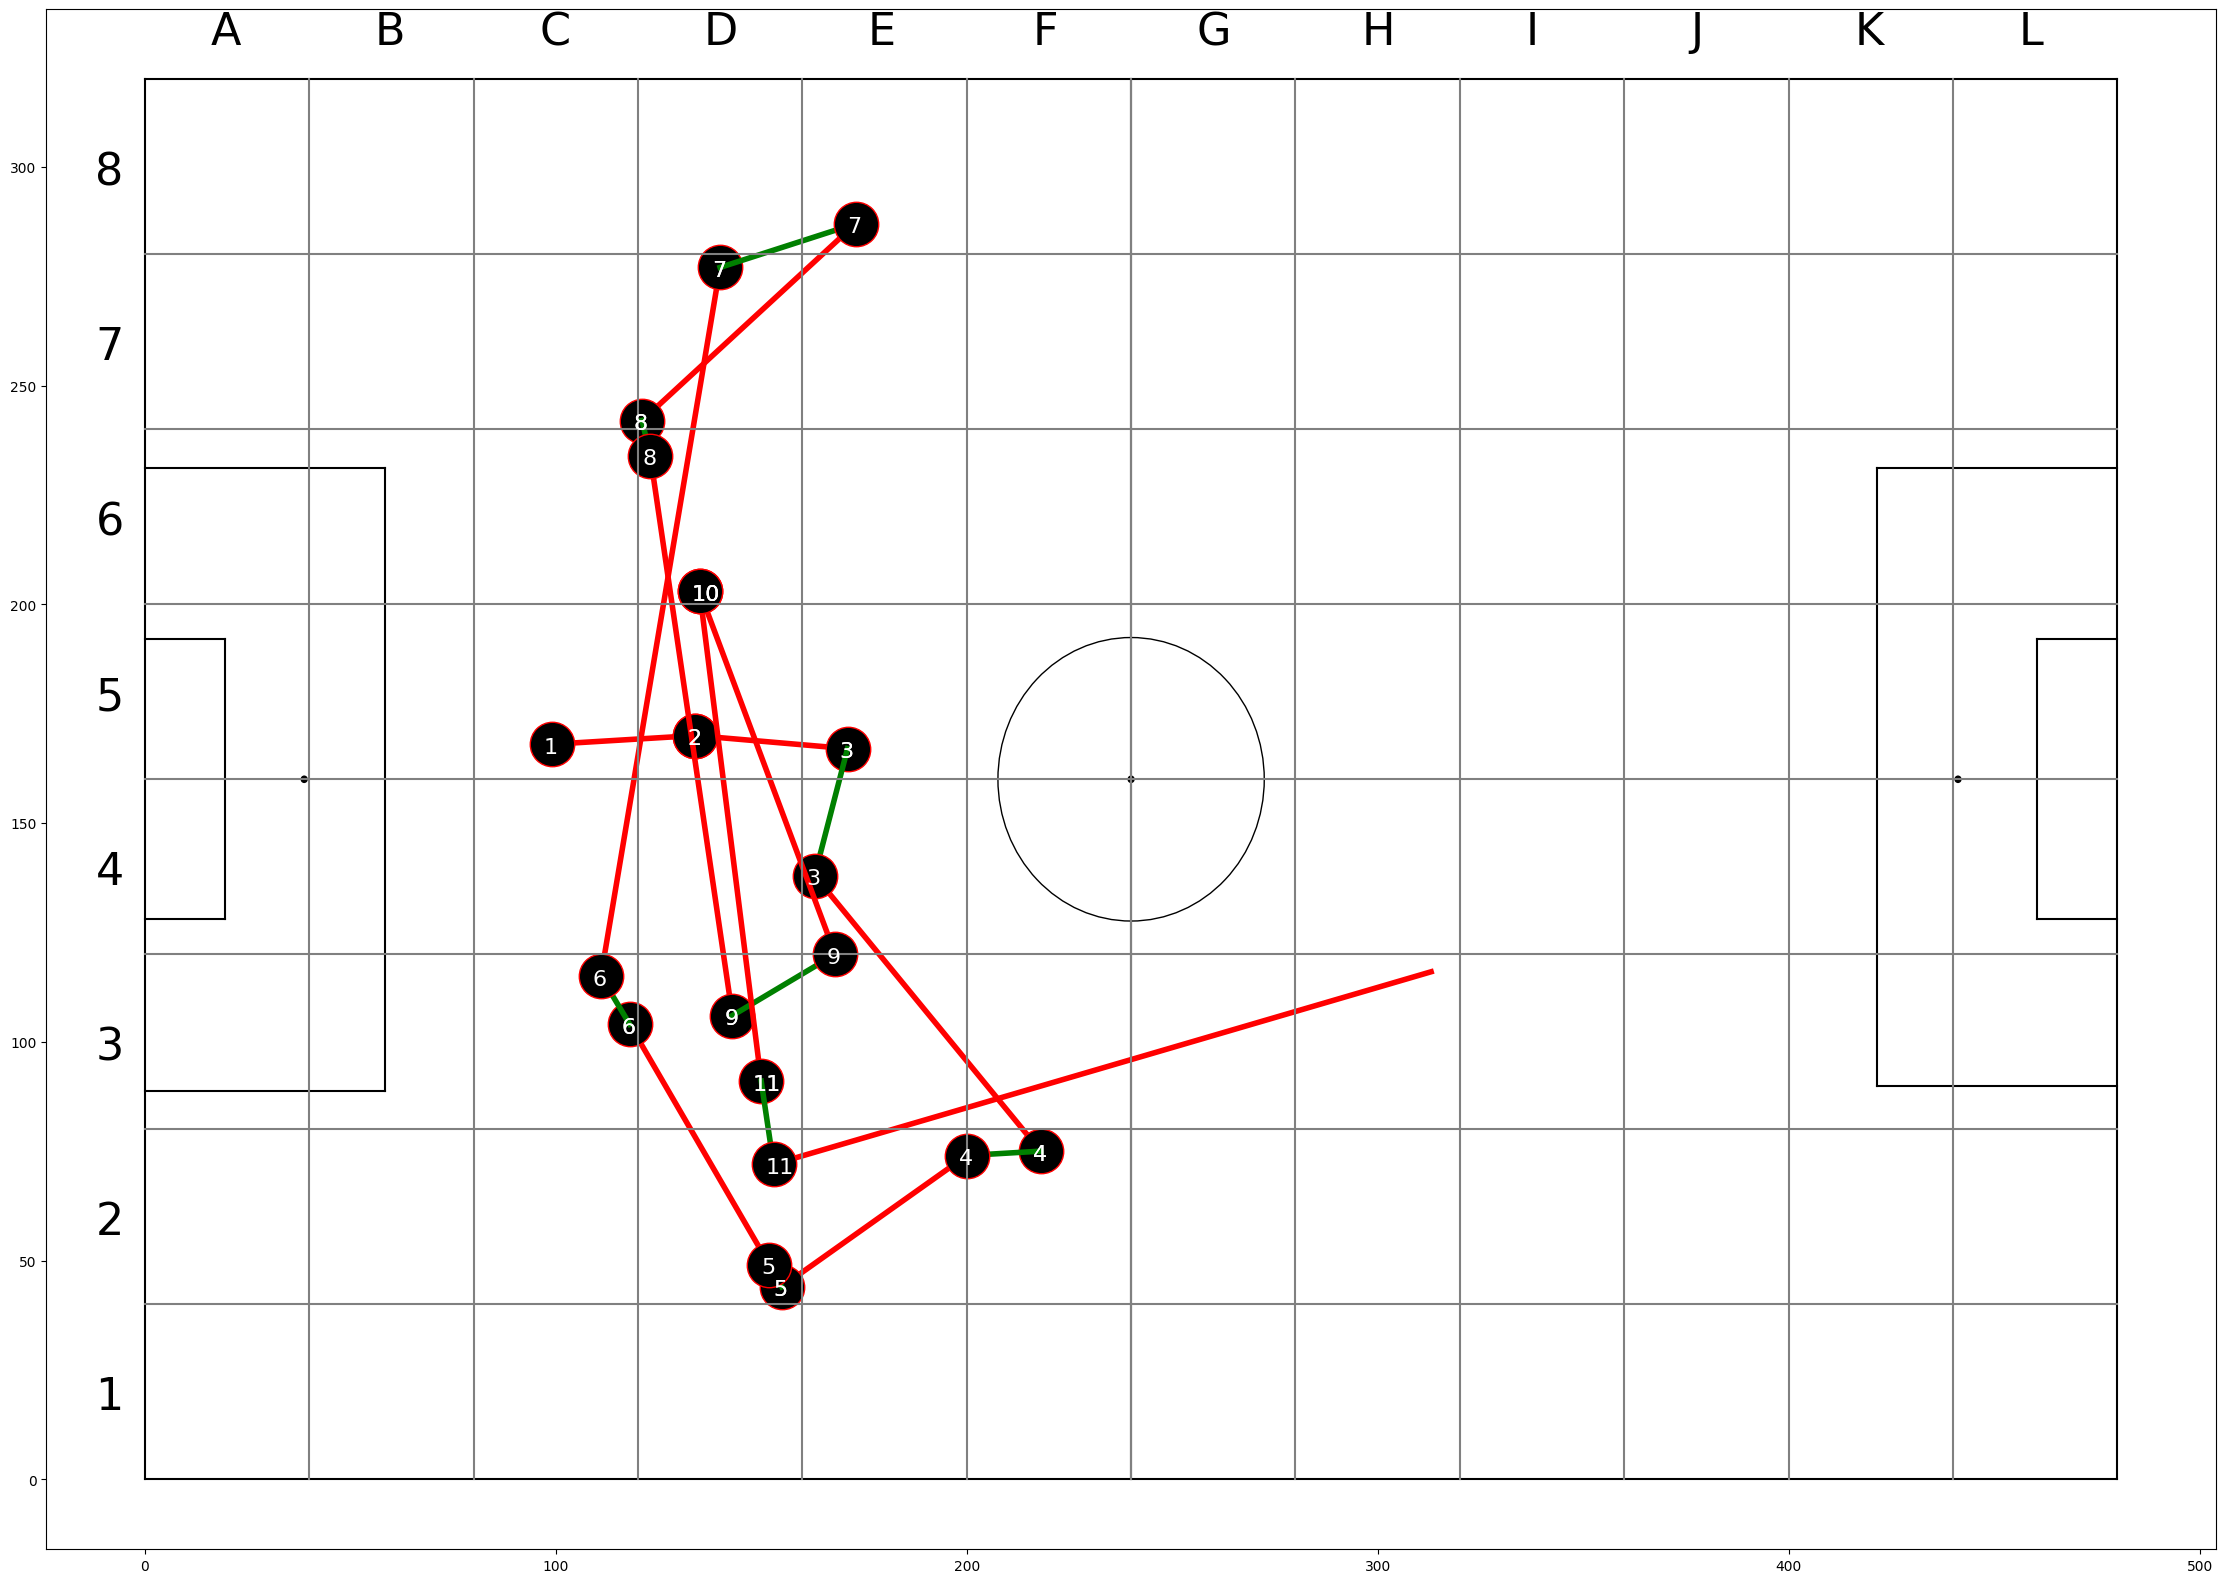

Sequence: 3
Team: Sweden
1: Victor Nilsson Lindelöf (Pass) <00:00:38.375>
2: Kristoffer Olsson (Ball Receipt*) <00:00:39.466>
2: Kristoffer Olsson (Pass) <00:00:39.466>
3: Mikael Lustig (Ball Receipt*) <00:00:40.562>
3: Mikael Lustig (Carry) <00:00:40.562>
3: Mikael Lustig (Pass) <00:00:42.468>


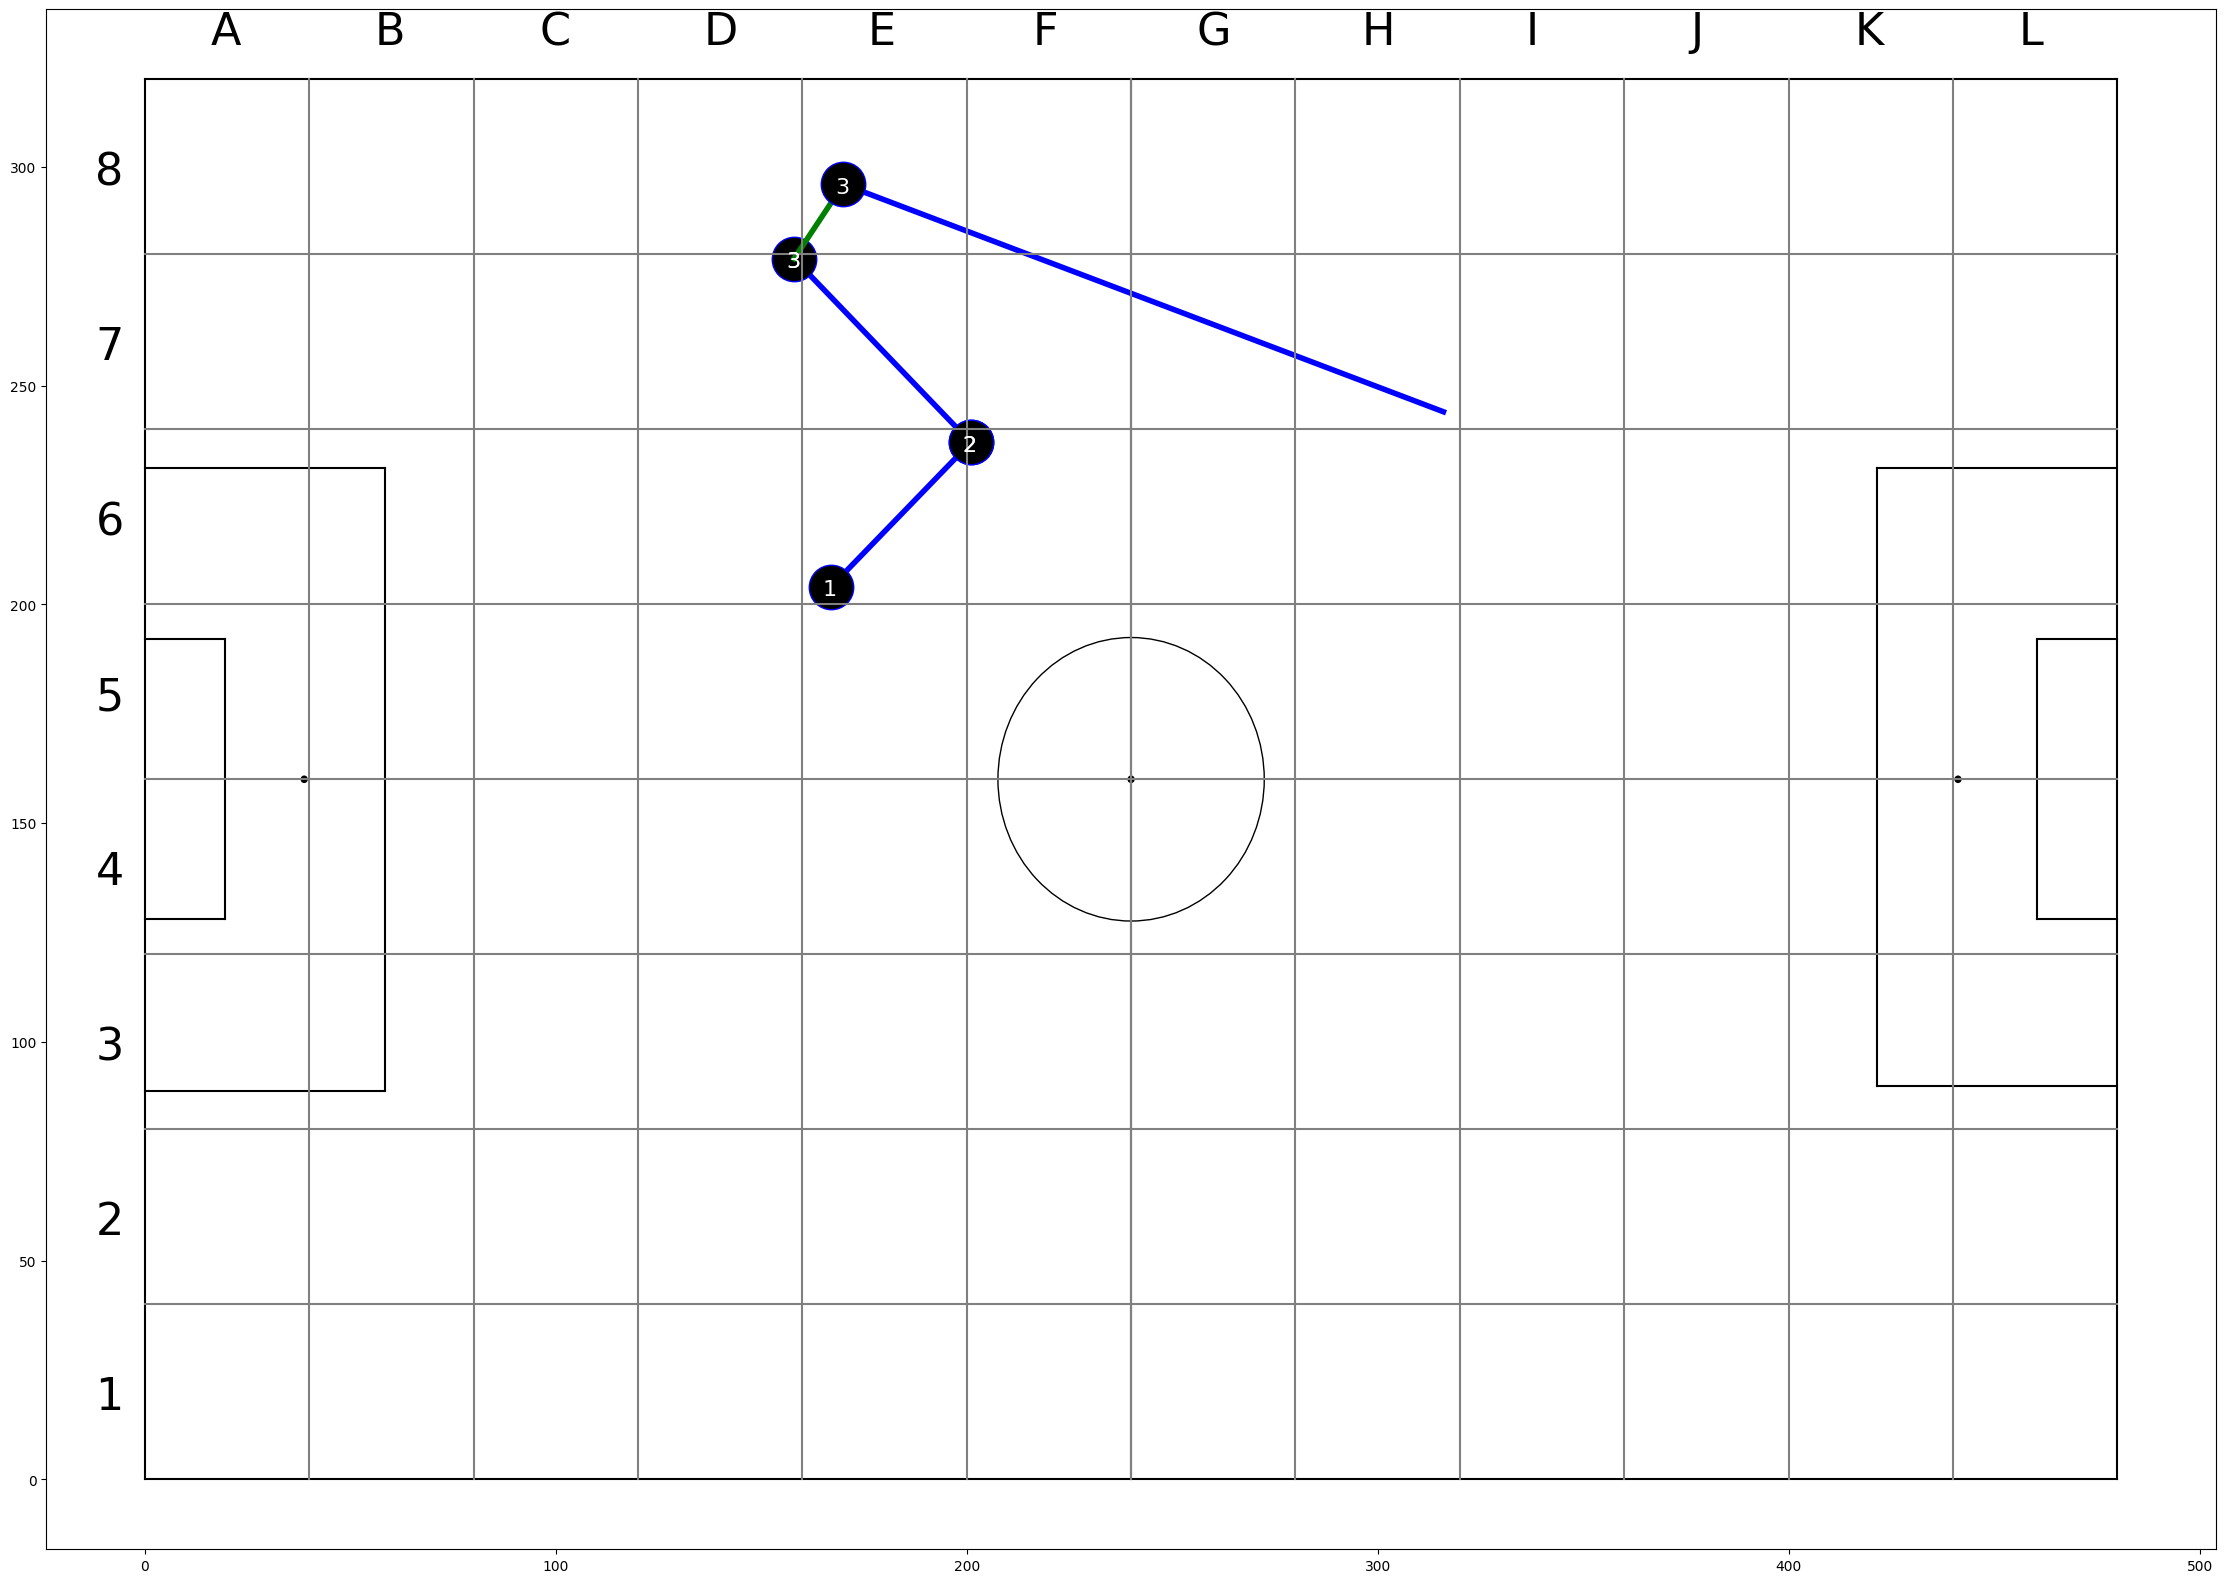

Sequence: 4
Team: Poland
1: Jan Bednarek (Pass) <00:00:44.270>
2: Grzegorz Krychowiak (Ball Receipt*) <00:00:45.101>
2: Grzegorz Krychowiak (Carry) <00:00:45.101>
2: Grzegorz Krychowiak (Pass) <00:00:46.473>
3: Tymoteusz Puchacz (Ball Receipt*) <00:00:47.194>
3: Tymoteusz Puchacz (Carry) <00:00:47.194>
3: Tymoteusz Puchacz (Pass) <00:00:47.847>
4: Mateusz Andrzej Klich (Ball Receipt*) <00:00:48.794>
4: Mateusz Andrzej Klich (Carry) <00:00:48.794>
4: Mateusz Andrzej Klich (Dispossessed) <00:00:50.138>
5: Mikael Lustig (Duel) <00:00:50.138>


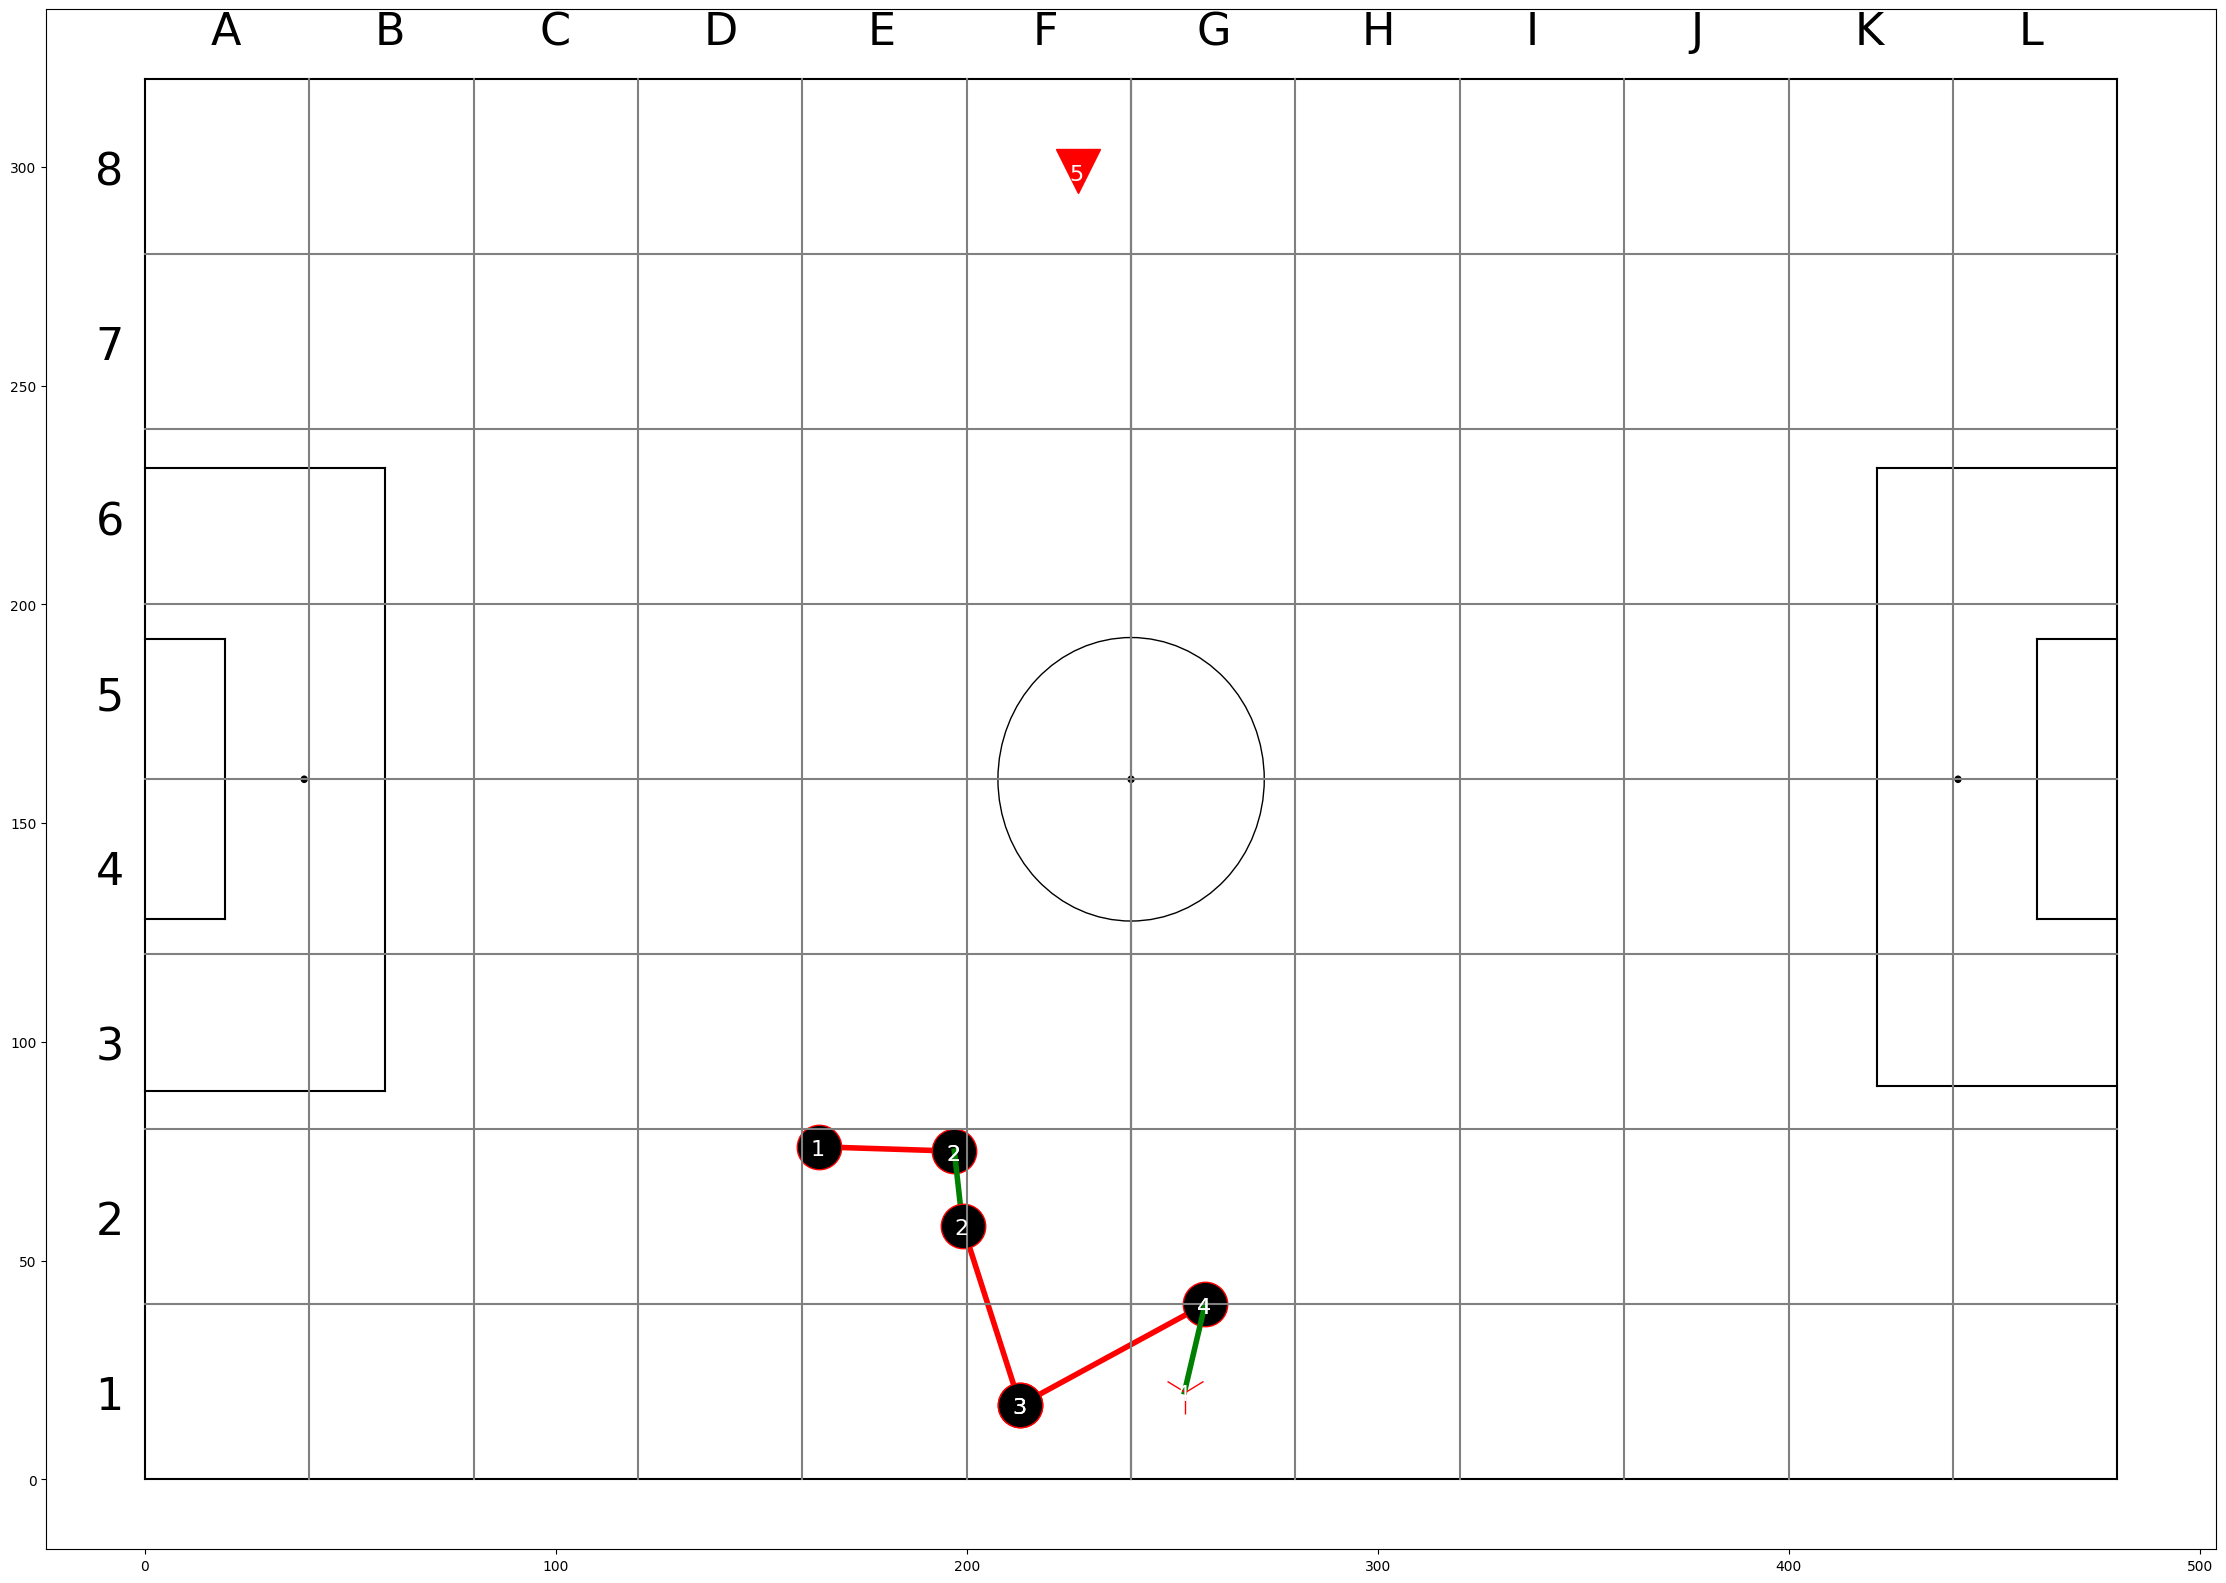

Sequence: 5
Team: Sweden
1: Mikael Lustig (Pass) <00:01:10.498>
2: Sebastian Larsson (Ball Receipt*) <00:01:11.479>
2: Sebastian Larsson (Pass) <00:01:11.479>
3: Mikael Lustig (Ball Receipt*) <00:01:12.472>
3: Mikael Lustig (Pass) <00:01:12.472>
4: Sebastian Larsson (Ball Receipt*) <00:01:13.070>
4: Sebastian Larsson (Pass) <00:01:13.070>
5: Mikael Lustig (Ball Receipt*) <00:01:14.119>
5: Mikael Lustig (Carry) <00:01:14.119>
5: Mikael Lustig (Pass) <00:01:15.083>
6: Alexander Isak (Ball Receipt*) <00:01:16.569>
6: Alexander Isak (Carry) <00:01:16.569>
6: Alexander Isak (Pass) <00:01:16.577>
7: Emil Peter Forsberg (Ball Receipt*) <00:01:17.827>
7: Emil Peter Forsberg (Carry) <00:01:17.827>
7: Emil Peter Forsberg (Pass) <00:01:17.830>
8: Alexander Isak (Ball Receipt*) <00:01:18.888>
8: Alexander Isak (Carry) <00:01:18.888>
8: Alexander Isak (Dispossessed) <00:01:19.168>
9: Kamil Glik (Duel) <00:01:19.168>
10: Emil Peter Forsberg (Pass) <00:01:19.483>
11: Alexander Isak (Ball Receipt*) <0

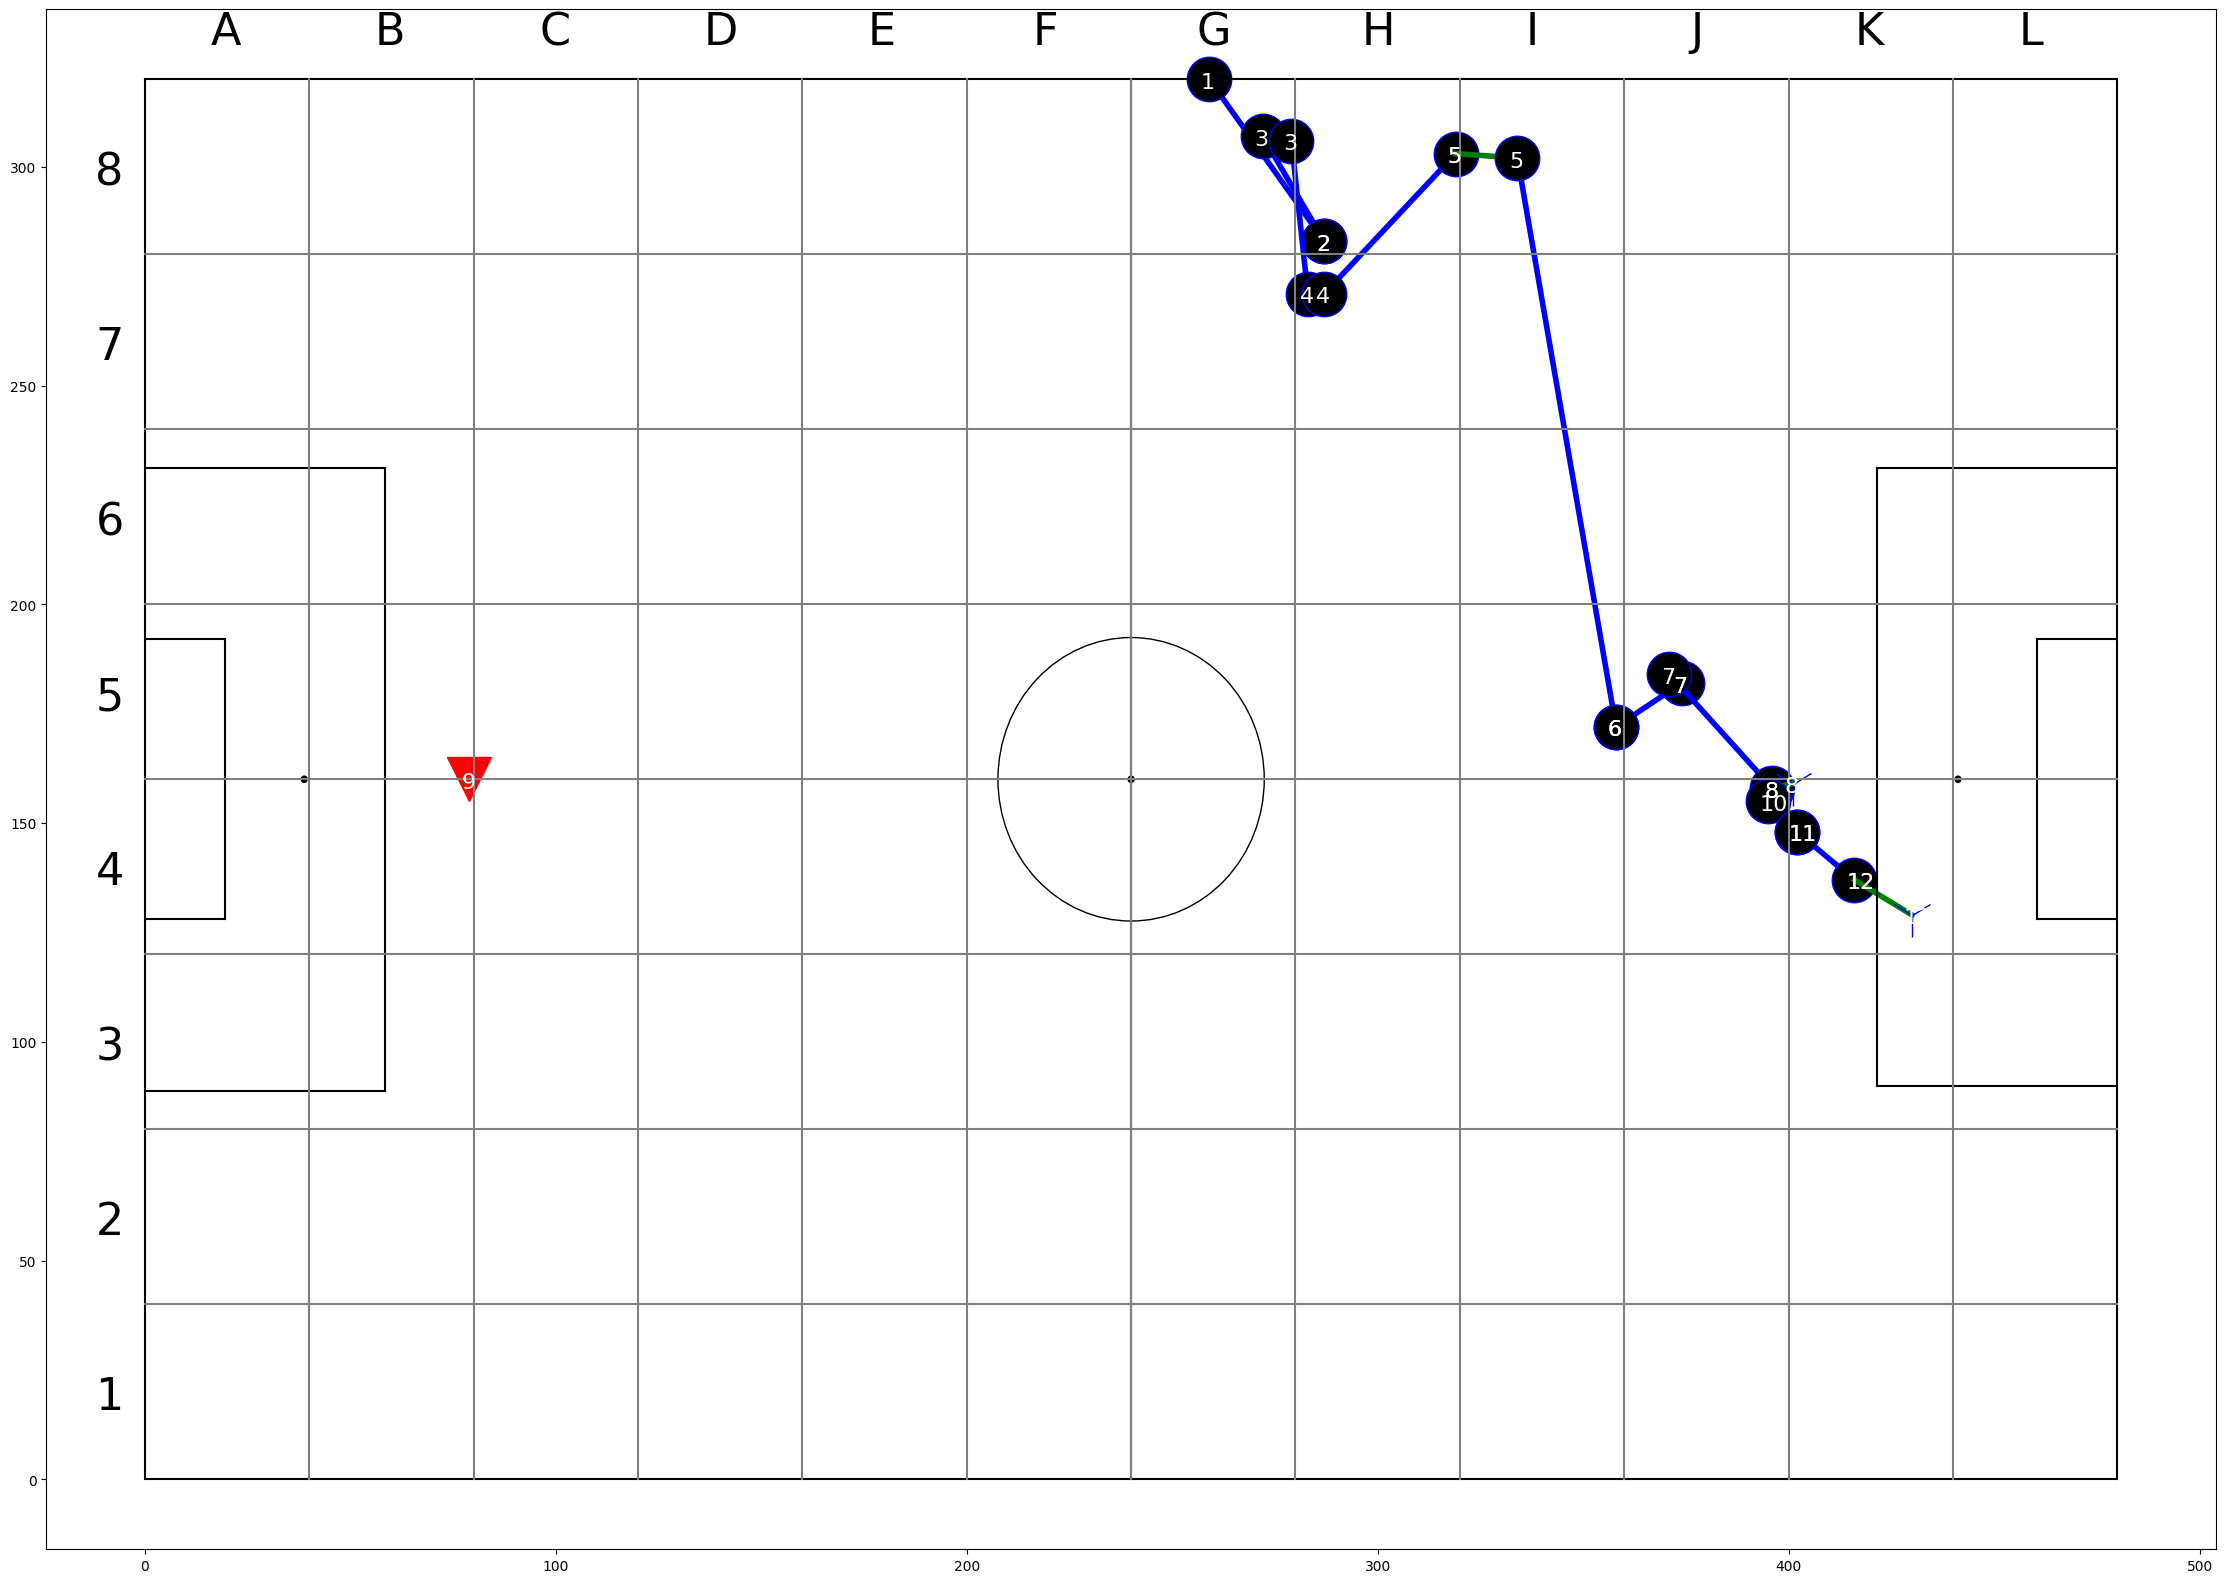

Sequence: 6
Team: Poland
1: Robert Lewandowski (Pass) <00:02:17.362>
2: Kamil Glik (Ball Receipt*) <00:02:19.016>
2: Kamil Glik (Pass) <00:02:21.722>
3: Jan Bednarek (Ball Receipt*) <00:02:23.028>
3: Jan Bednarek (Carry) <00:02:23.028>
3: Jan Bednarek (Pass) <00:02:25.583>
4: Kamil Glik (Ball Receipt*) <00:02:27.086>
4: Kamil Glik (Carry) <00:02:27.086>
4: Kamil Glik (Pass) <00:02:30.217>
5: Jan Bednarek (Ball Receipt*) <00:02:32.147>
5: Jan Bednarek (Carry) <00:02:32.147>
5: Jan Bednarek (Pass) <00:02:33.891>
6: Robert Lewandowski (Ball Receipt*) <00:02:36.609>


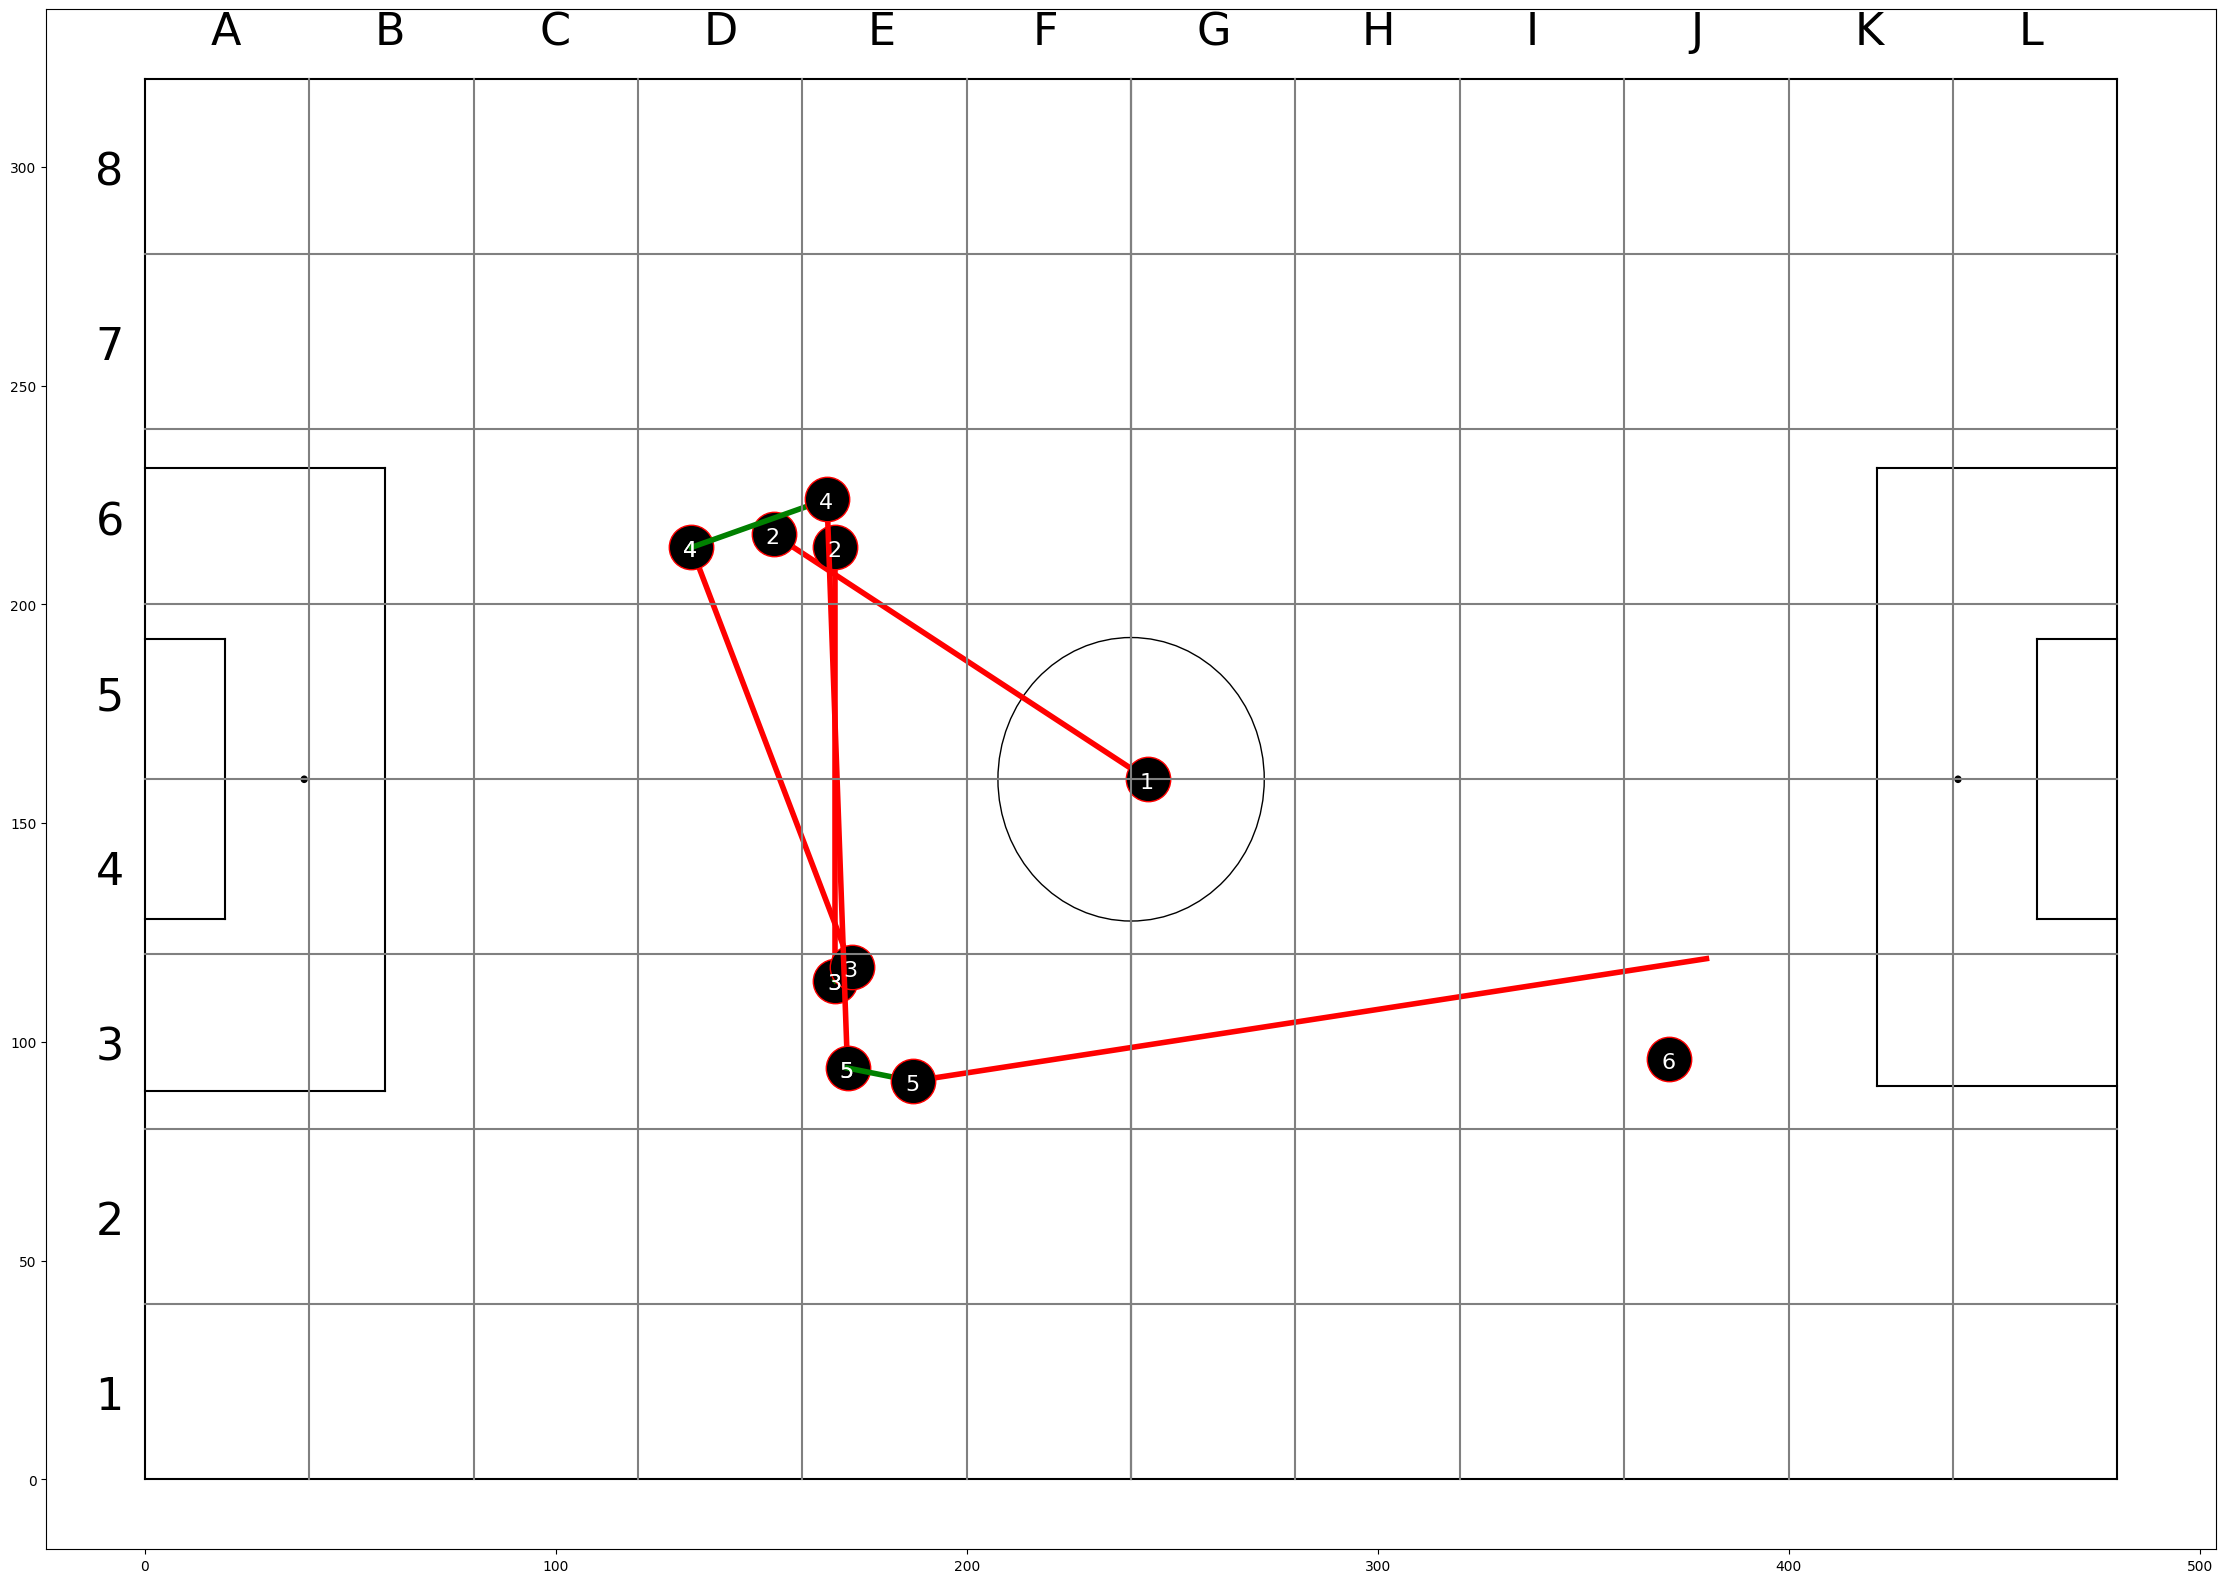

Sequence: 7
Team: Sweden
1: Victor Nilsson Lindelöf (Pass) <00:02:36.609>
2: Mikael Lustig (Ball Receipt*) <00:02:38.606>
2: Mikael Lustig (Carry) <00:02:38.606>
2: Mikael Lustig (Pass) <00:02:40.897>
3: Alexander Isak (Ball Receipt*) <00:02:43.264>
3: Alexander Isak (Duel) <00:02:43.264>
4: Kamil Glik (Pass) <00:02:43.264>
5: Mikael Lustig (Pass) <00:02:58.958>
6: Sebastian Larsson (Ball Receipt*) <00:03:00.252>
6: Sebastian Larsson (Carry) <00:03:00.252>
6: Sebastian Larsson (Pass) <00:03:00.268>
7: Mikael Lustig (Ball Receipt*) <00:03:01.146>
7: Mikael Lustig (Pass) <00:03:01.146>
8: Sebastian Larsson (Ball Receipt*) <00:03:01.294>
9: Piotr Zieliński (Block) <00:03:01.294>
10: Mikael Lustig (Pass) <00:03:11.677>
11: Kristoffer Olsson (Ball Receipt*) <00:03:12.556>
11: Kristoffer Olsson (Pass) <00:03:12.556>
12: Mikael Lustig (Ball Receipt*) <00:03:13.491>
12: Mikael Lustig (Pass) <00:03:13.491>
13: Robin Quaison (Ball Receipt*) <00:03:16.503>
14: Kamil Glik (Pass) <00:03:16.503>
15:

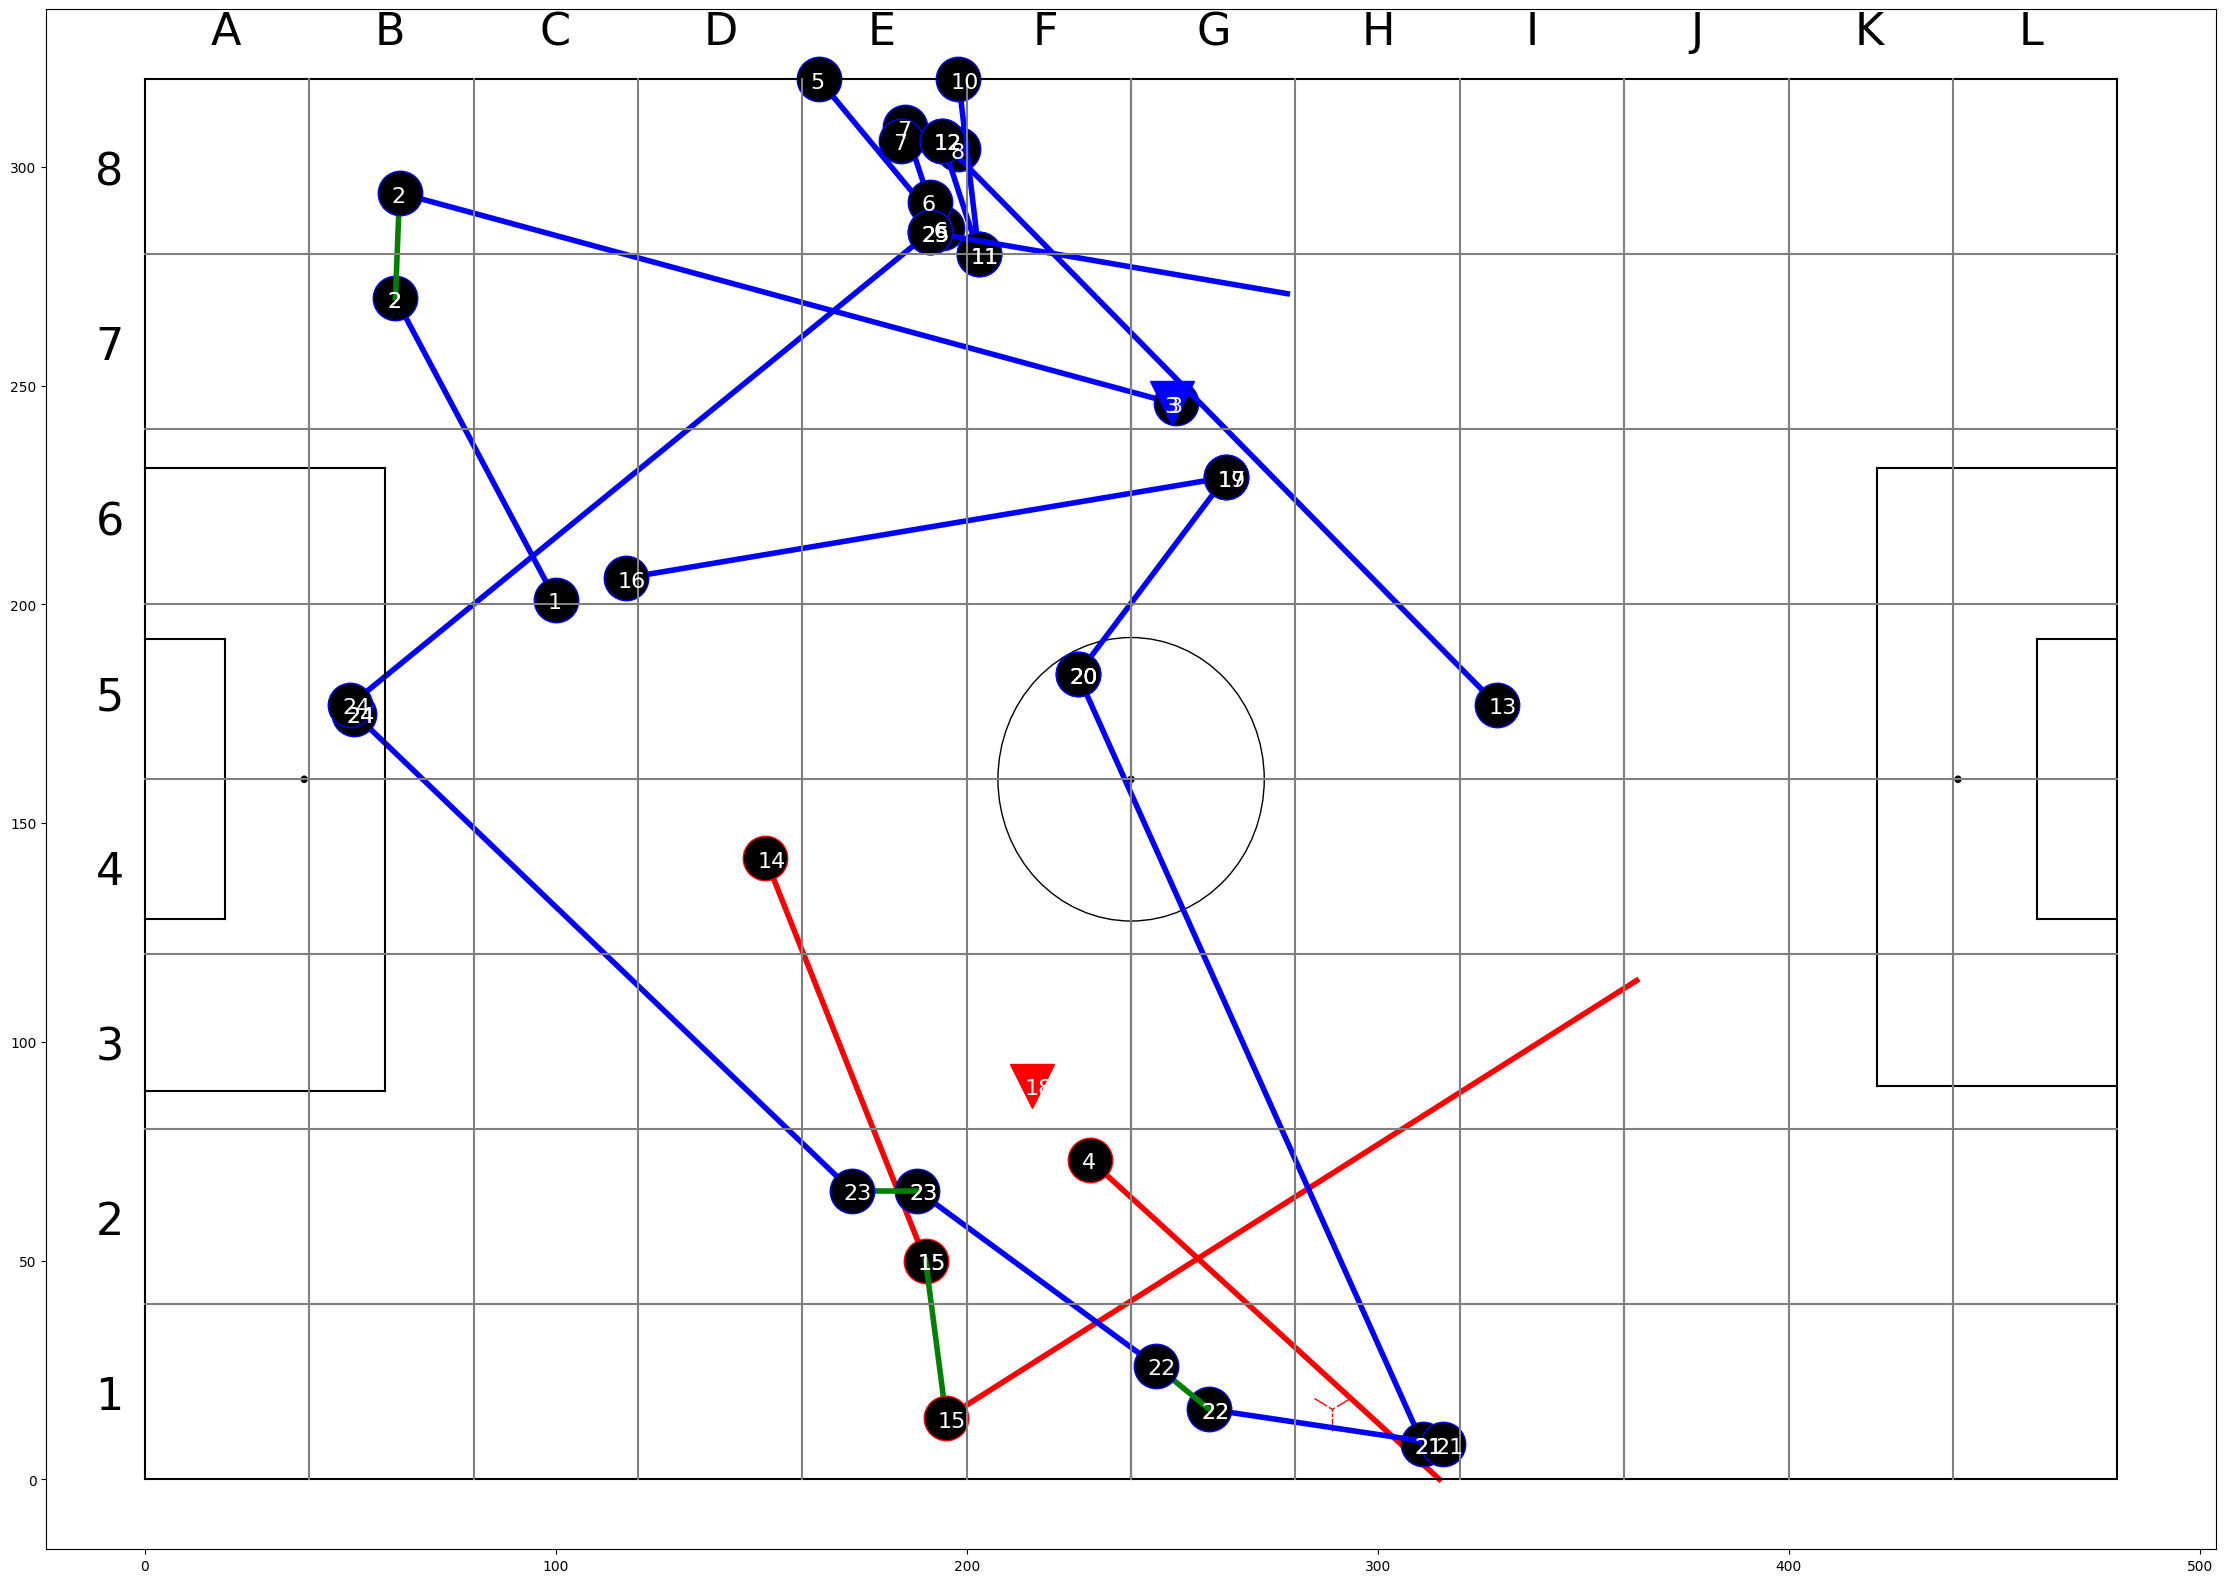

Sequence: 8
Team: Poland
1: Jan Bednarek (Pass) <00:03:53.358>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:03:54.025>
2: Mateusz Andrzej Klich (Carry) <00:03:54.025>
2: Mateusz Andrzej Klich (Pass) <00:03:54.063>
3: Grzegorz Krychowiak (Ball Receipt*) <00:03:55.019>
3: Grzegorz Krychowiak (Pass) <00:03:55.019>


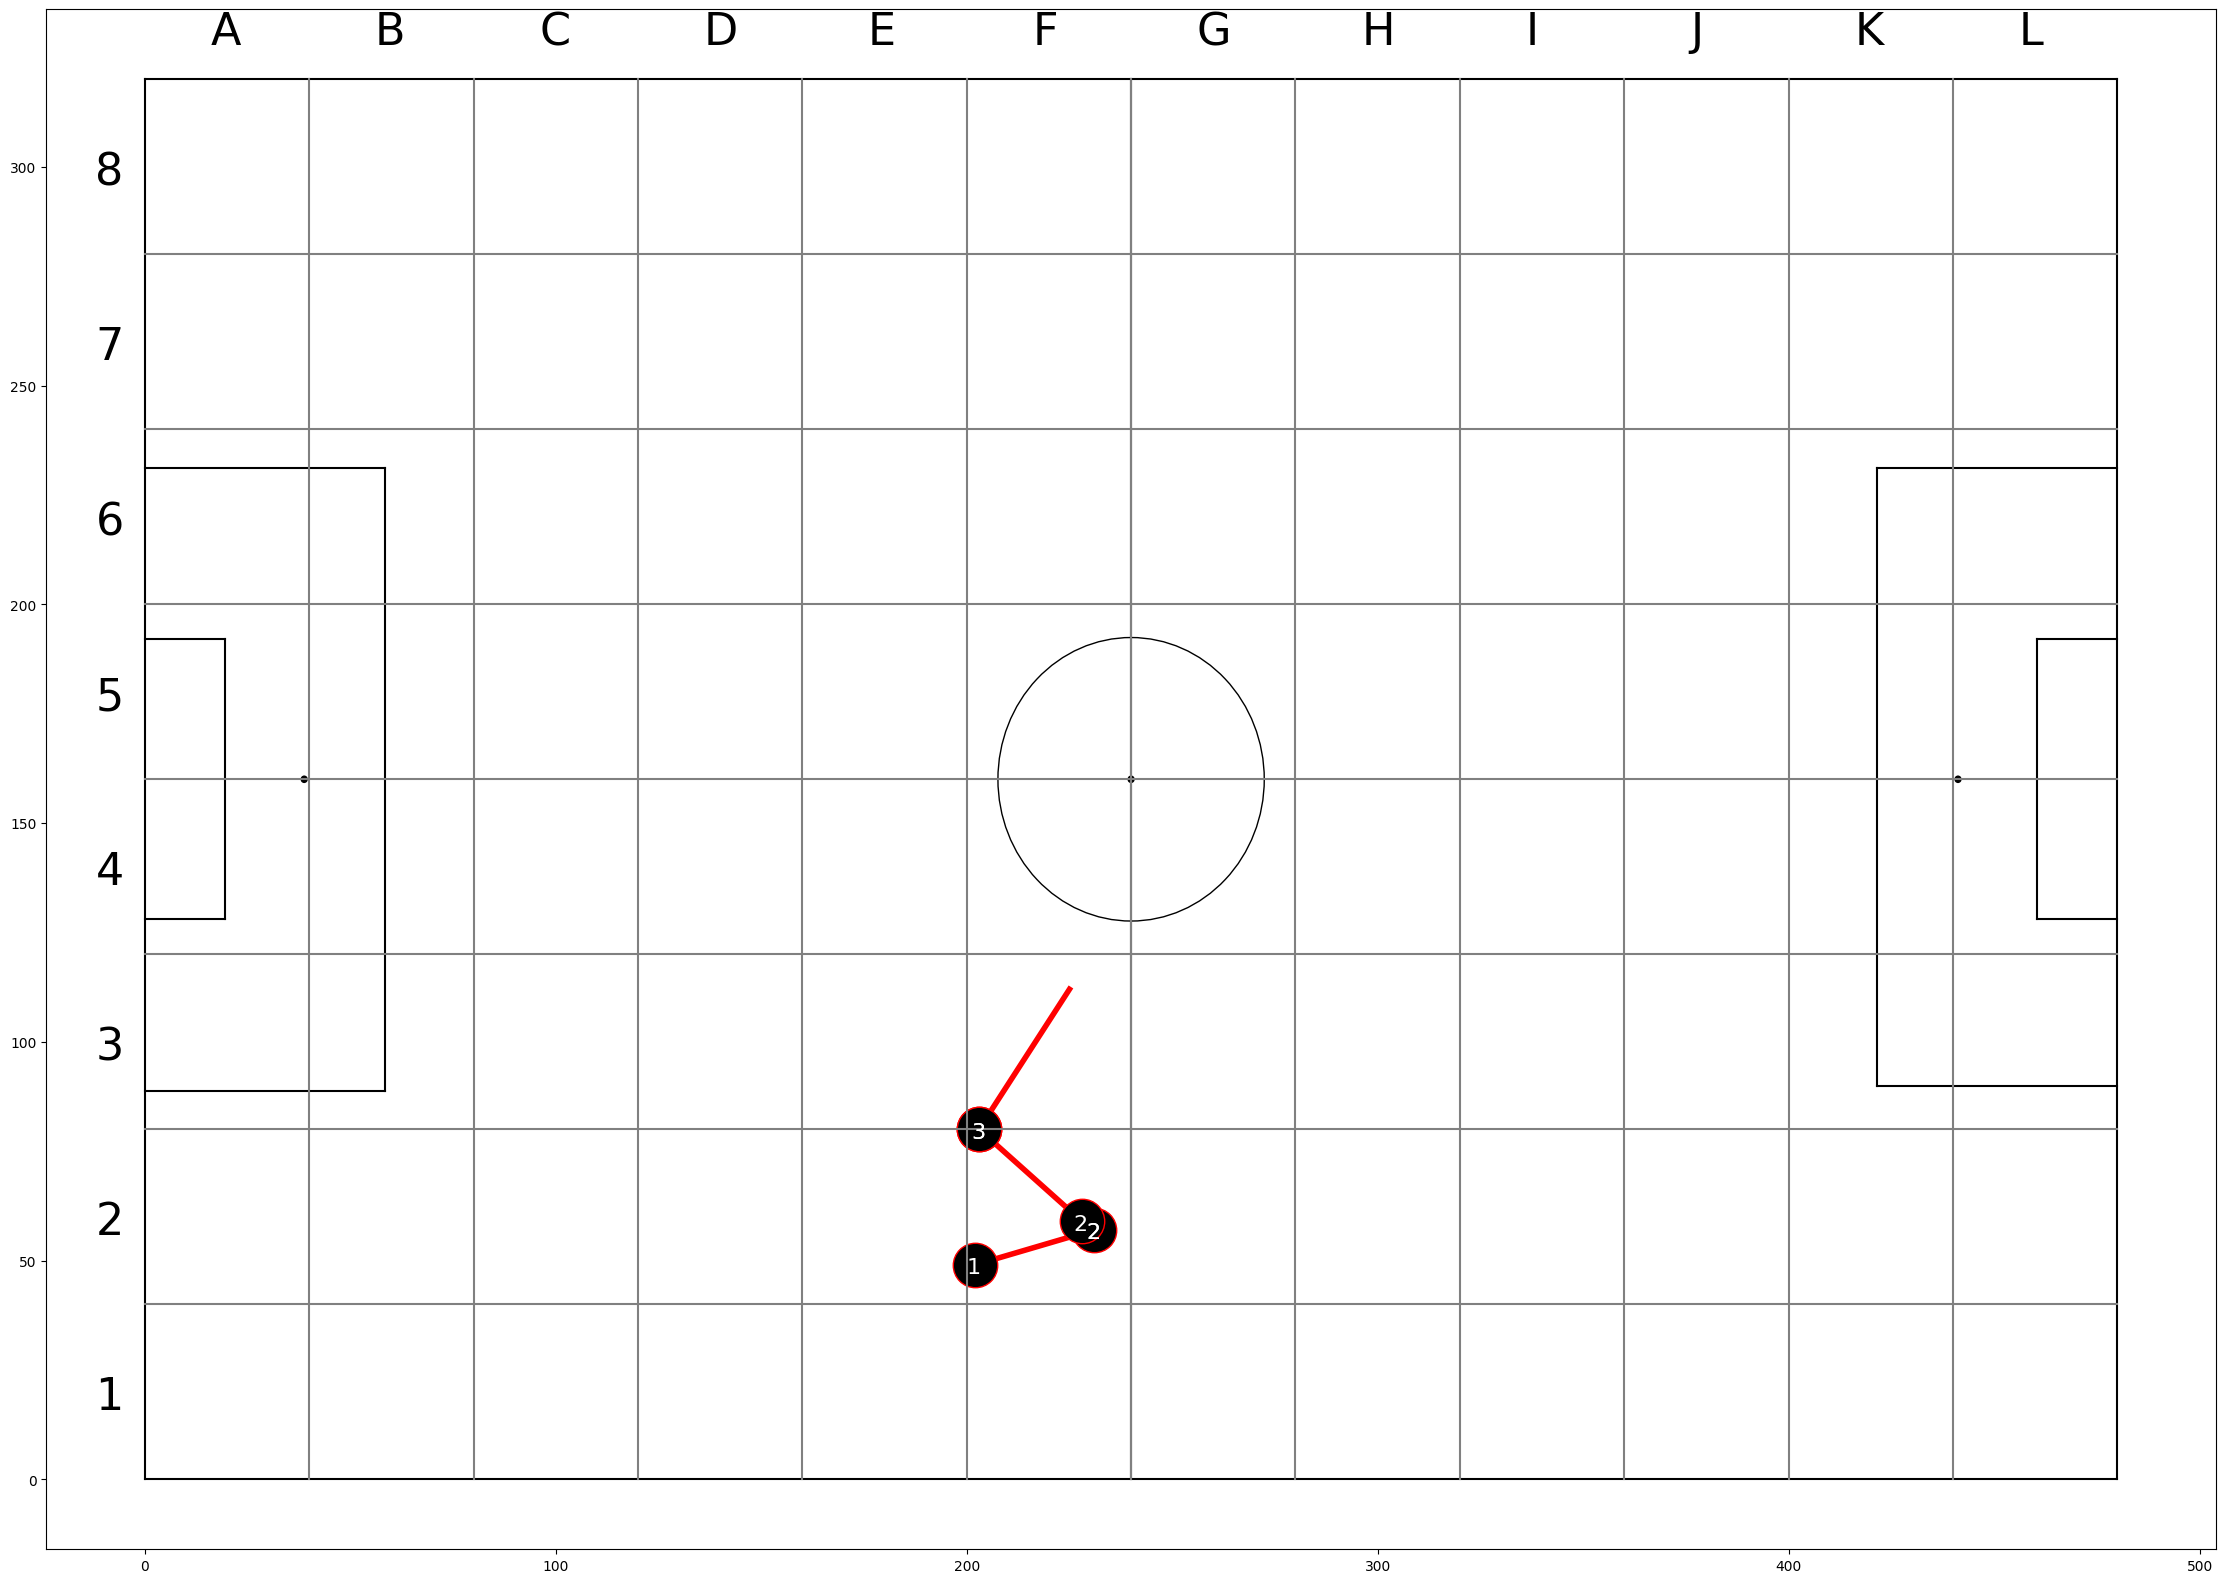

Sequence: 9
Team: Sweden
1: Kristoffer Olsson (Pass) <00:03:57.065>
2: Emil Peter Forsberg (Ball Receipt*) <00:03:58.111>
2: Emil Peter Forsberg (Carry) <00:03:58.111>
2: Emil Peter Forsberg (Pass) <00:04:01.108>
3: Ludwig Augustinsson (Ball Receipt*) <00:04:02.667>
3: Ludwig Augustinsson (Carry) <00:04:02.667>
3: Ludwig Augustinsson (Pass) <00:04:06.061>
4: Kristoffer Olsson (Ball Receipt*) <00:04:06.841>
4: Kristoffer Olsson (Carry) <00:04:06.841>
4: Kristoffer Olsson (Dispossessed) <00:04:06.879>
5: Bartosz Bereszyński (Duel) <00:04:06.879>
6: Kristoffer Olsson (Pass) <00:04:08.905>
7: Albin Ekdal (Ball Receipt*) <00:04:10.392>
7: Albin Ekdal (Pass) <00:04:10.392>
8: Ludwig Augustinsson (Ball Receipt*) <00:04:11.705>
8: Ludwig Augustinsson (Carry) <00:04:11.705>
8: Ludwig Augustinsson (Pass) <00:04:13.227>
9: Emil Peter Forsberg (Ball Receipt*) <00:04:13.915>
9: Emil Peter Forsberg (Carry) <00:04:13.915>
9: Emil Peter Forsberg (Dispossessed) <00:04:15.120>
10: Grzegorz Krychowiak (D

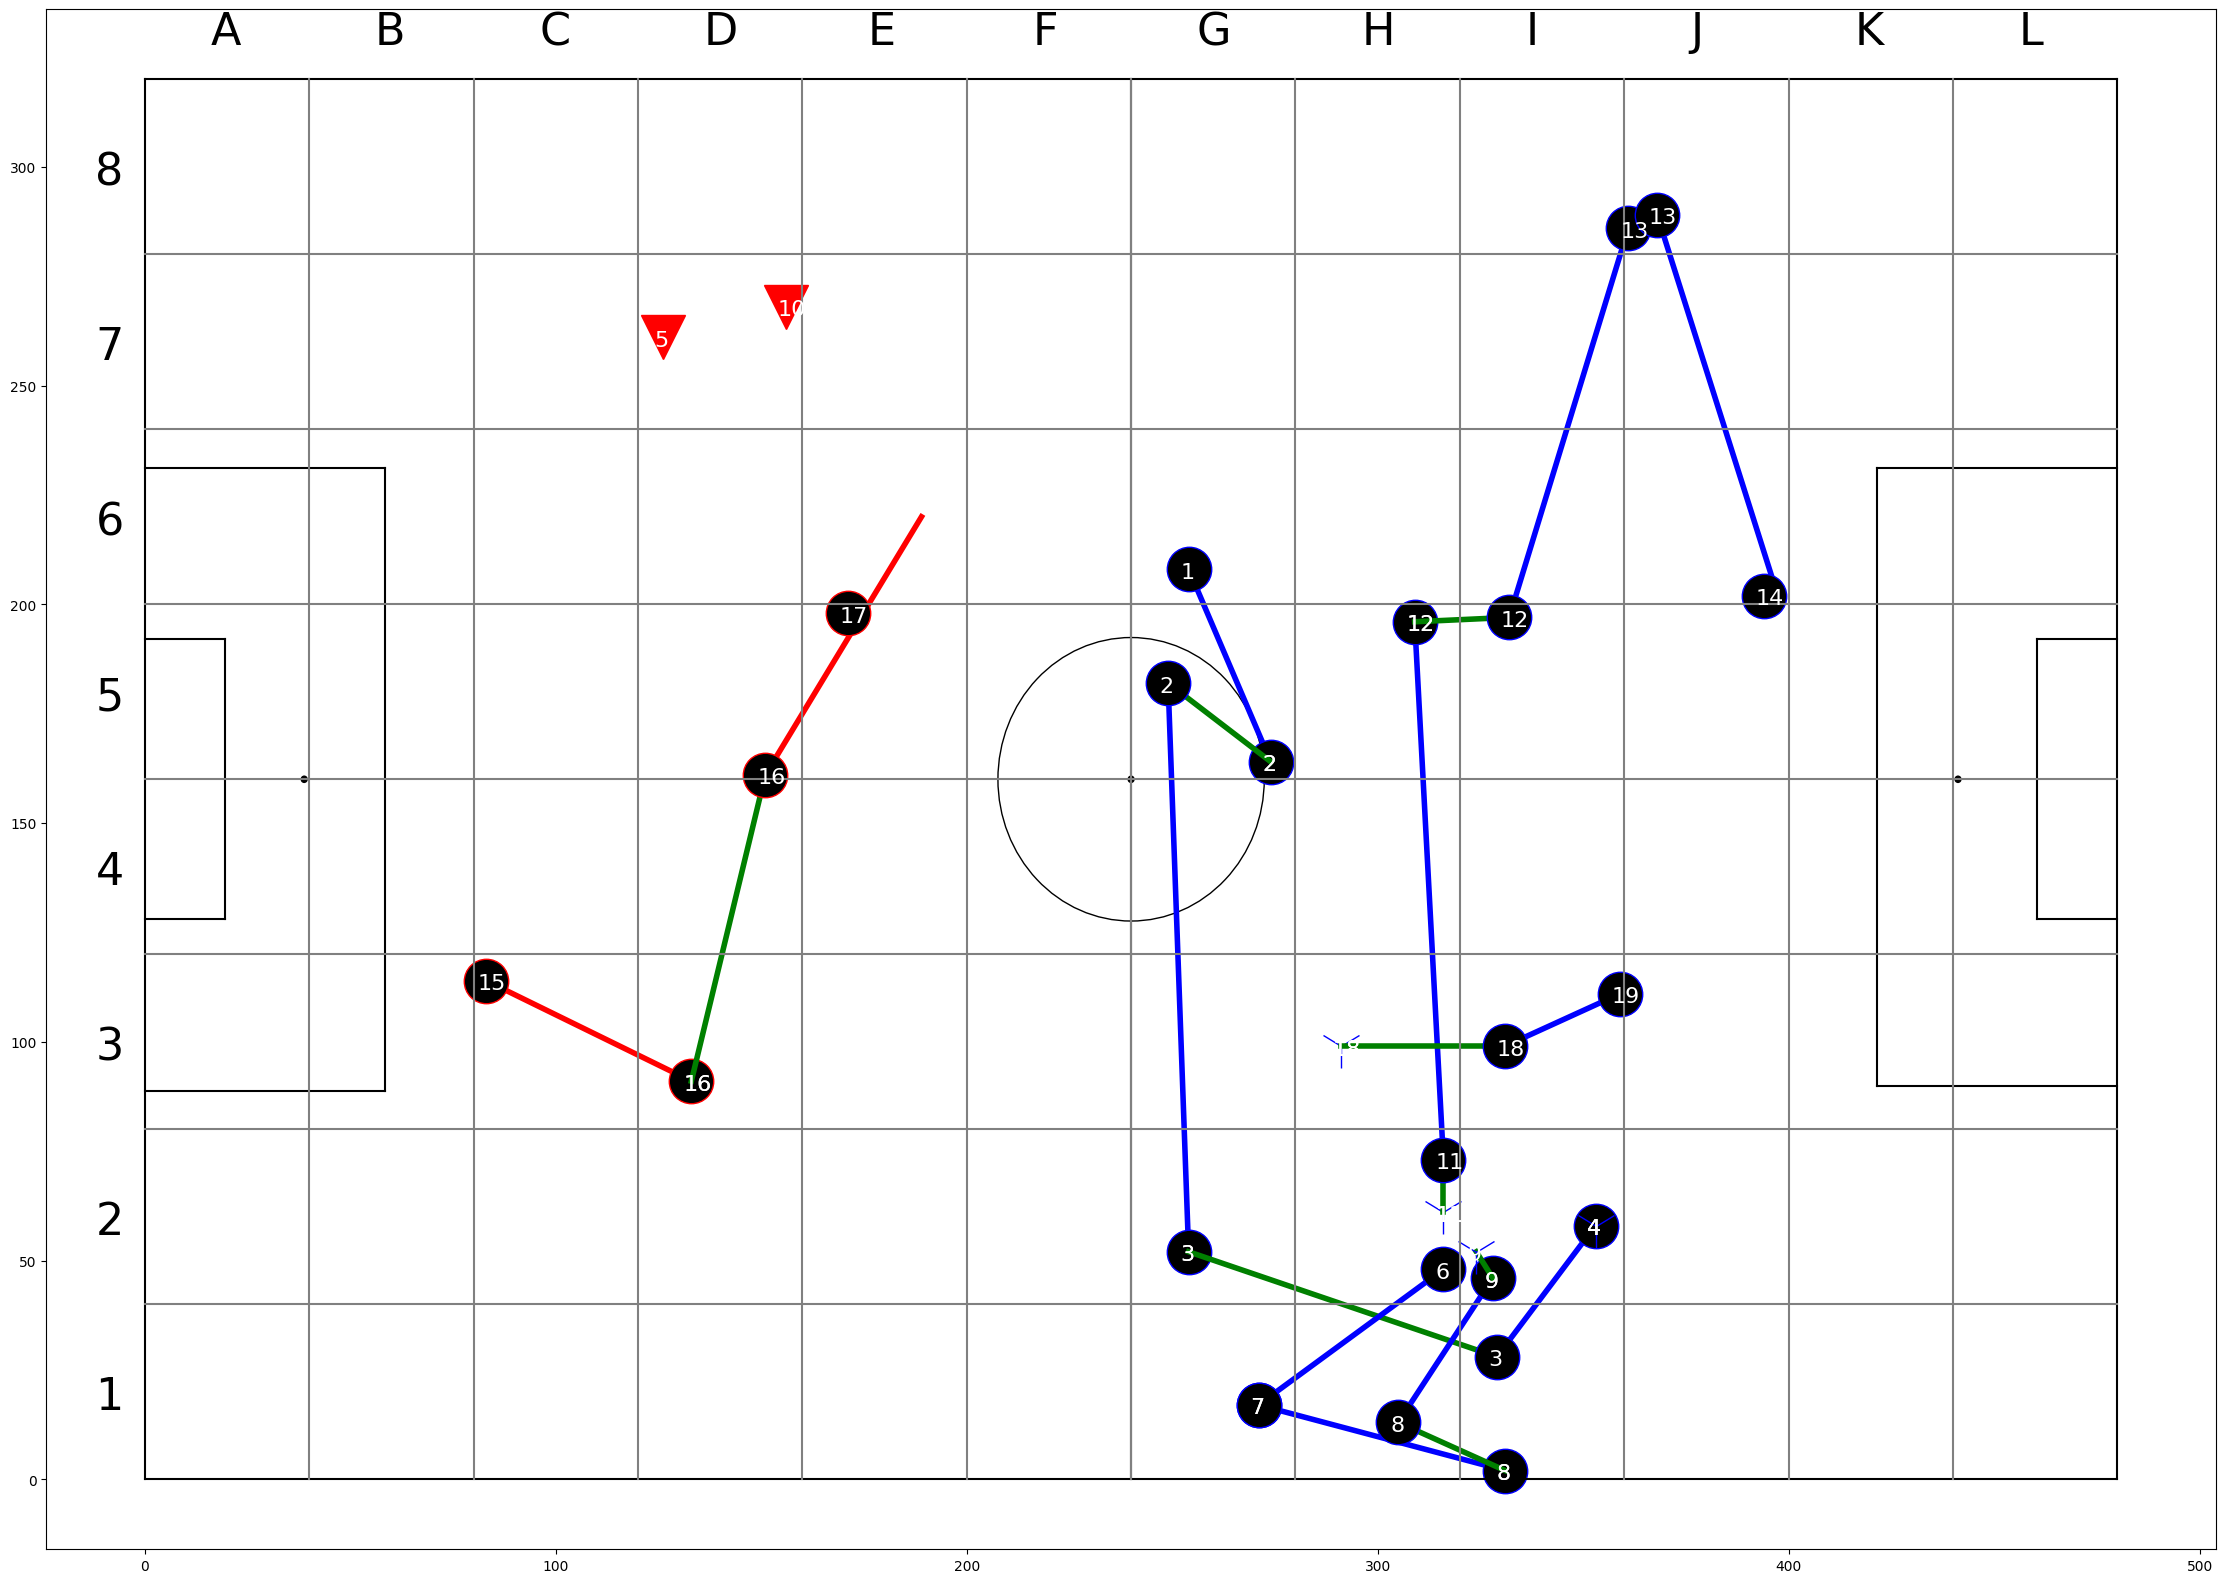

Sequence: 10
Team: Poland
1: Grzegorz Krychowiak (Interception) <00:04:34.047>
1: Grzegorz Krychowiak (Carry) <00:04:34.047>
1: Grzegorz Krychowiak (Pass) <00:04:35.567>
2: Karol Świderski (Ball Receipt*) <00:04:36.790>
2: Karol Świderski (Carry) <00:04:36.790>
2: Karol Świderski (Pass) <00:04:37.520>
3: Piotr Zieliński (Ball Receipt*) <00:04:38.289>
3: Piotr Zieliński (Carry) <00:04:38.289>
3: Piotr Zieliński (Pass) <00:04:39.143>
4: Kamil Jóźwiak (Ball Receipt*) <00:04:42.801>
4: Kamil Jóźwiak (Miscontrol) <00:04:42.801>


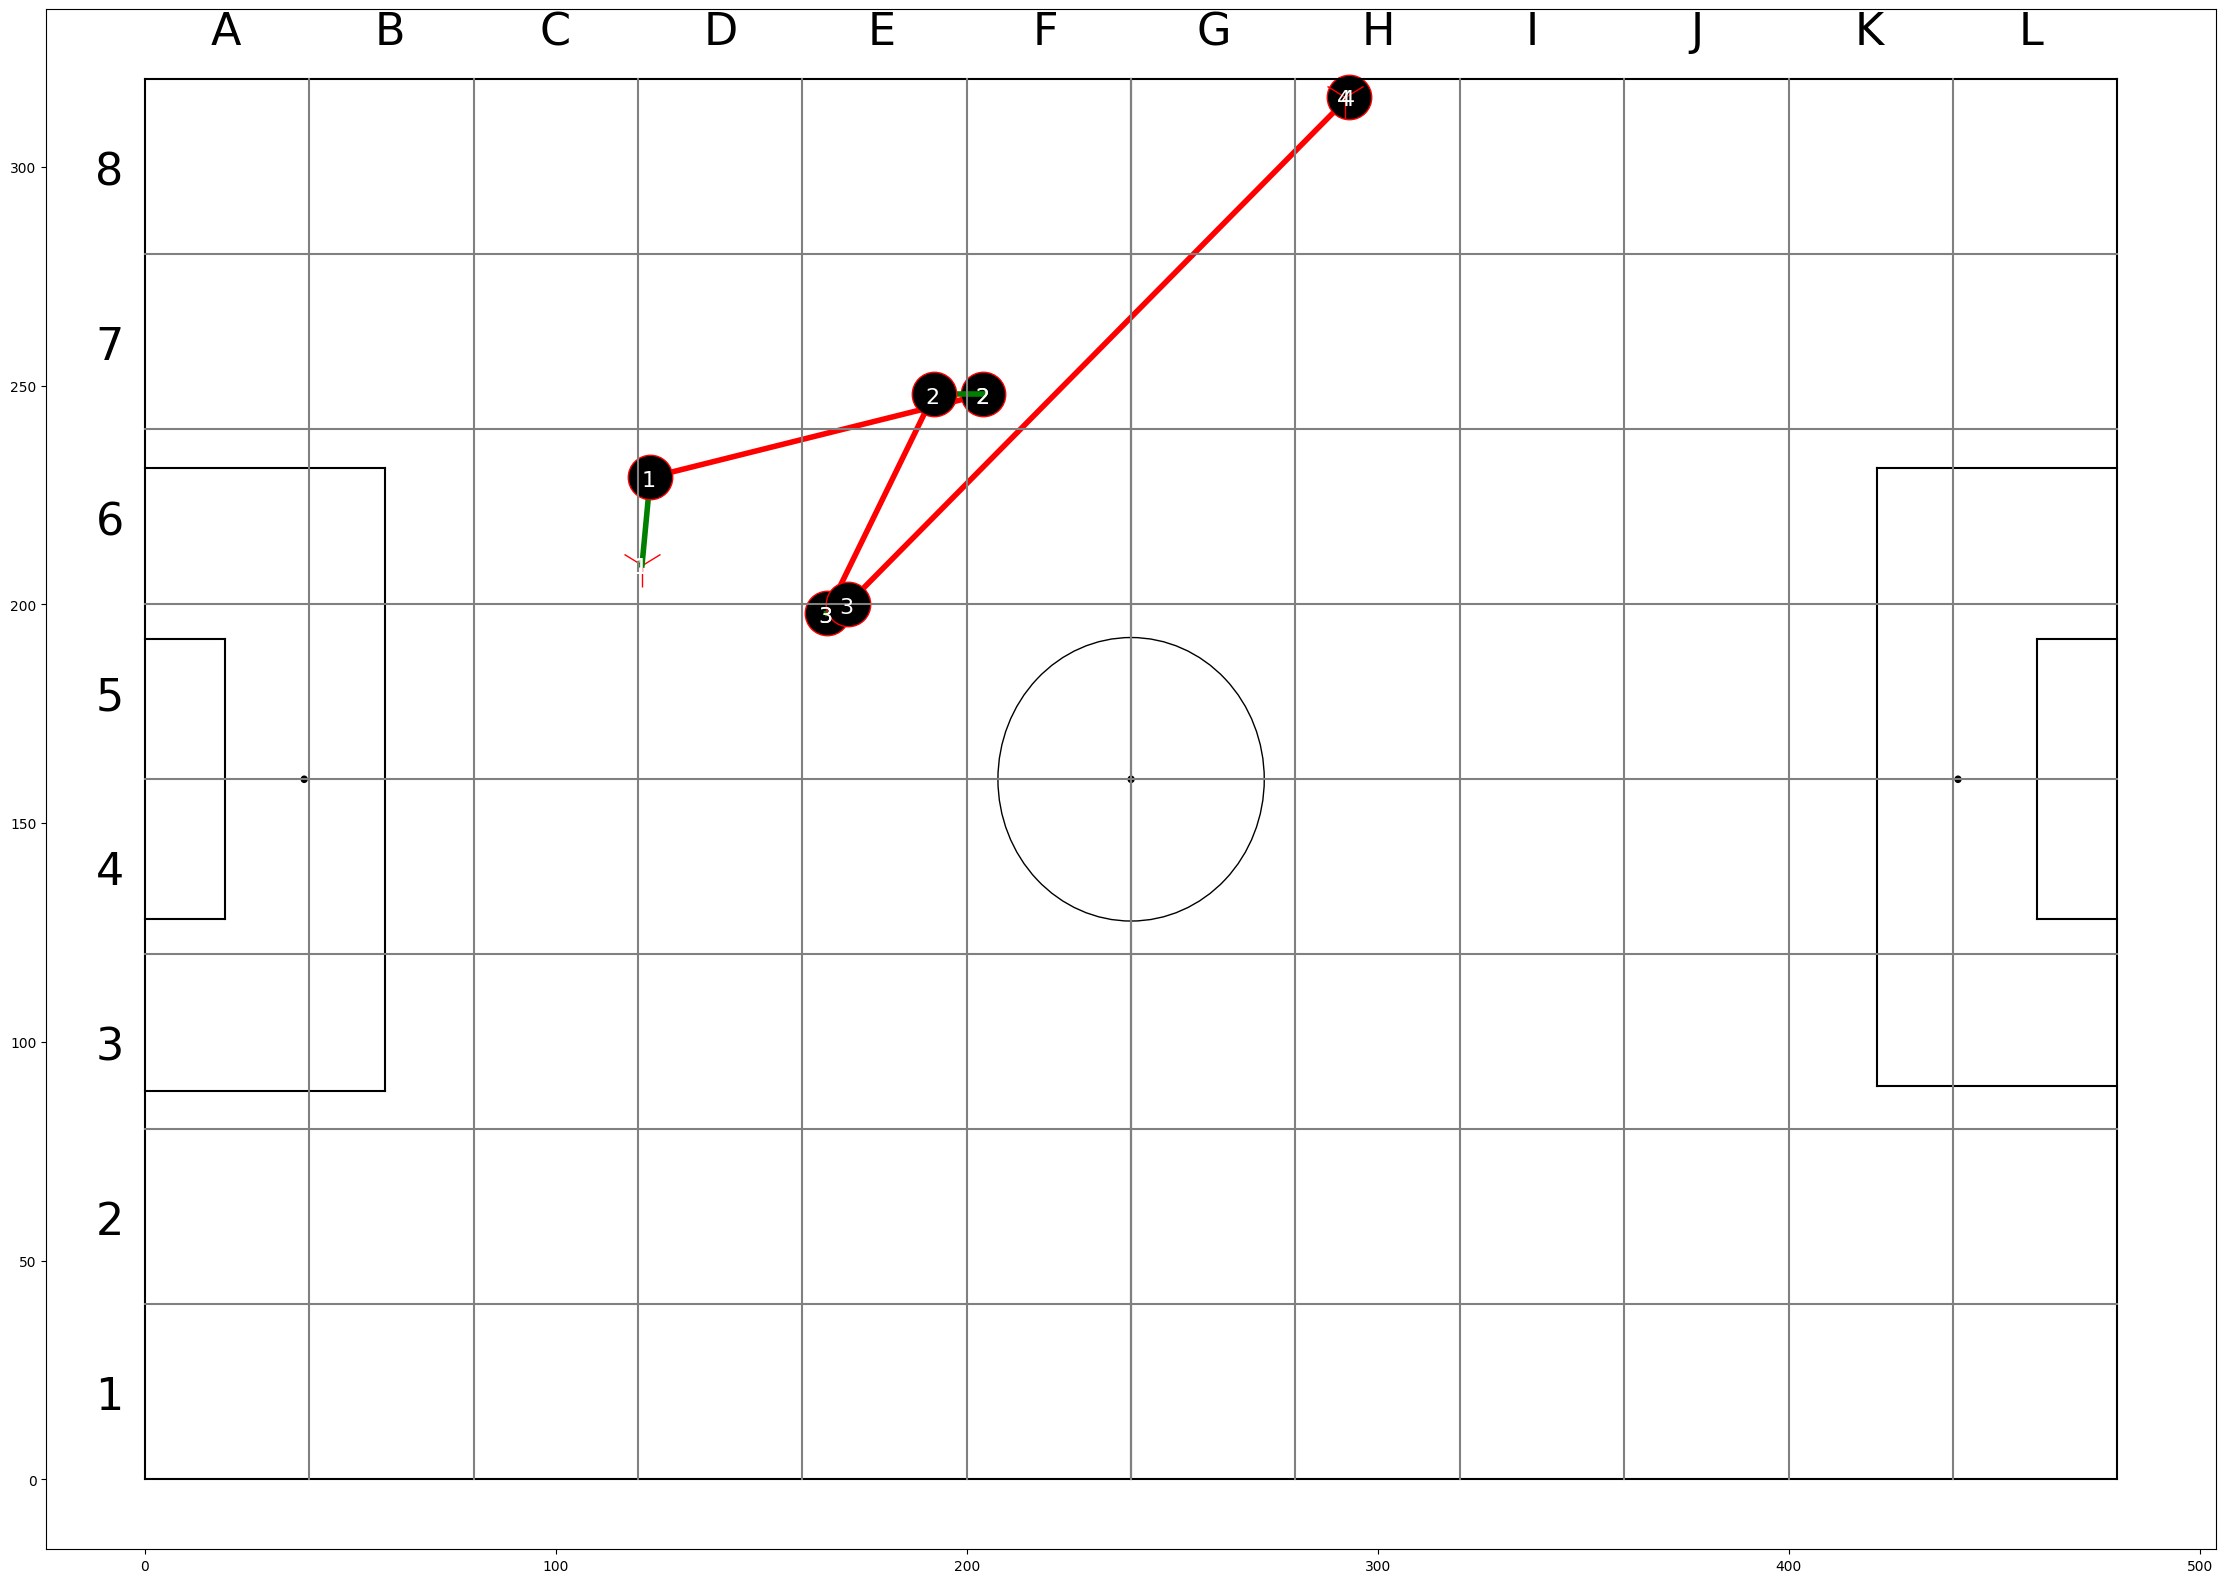

Sequence: 11
Team: Sweden
1: Ludwig Augustinsson (Pass) <00:05:11.130>
2: Alexander Isak (Ball Receipt*) <00:05:12.389>
2: Alexander Isak (Duel) <00:05:12.389>


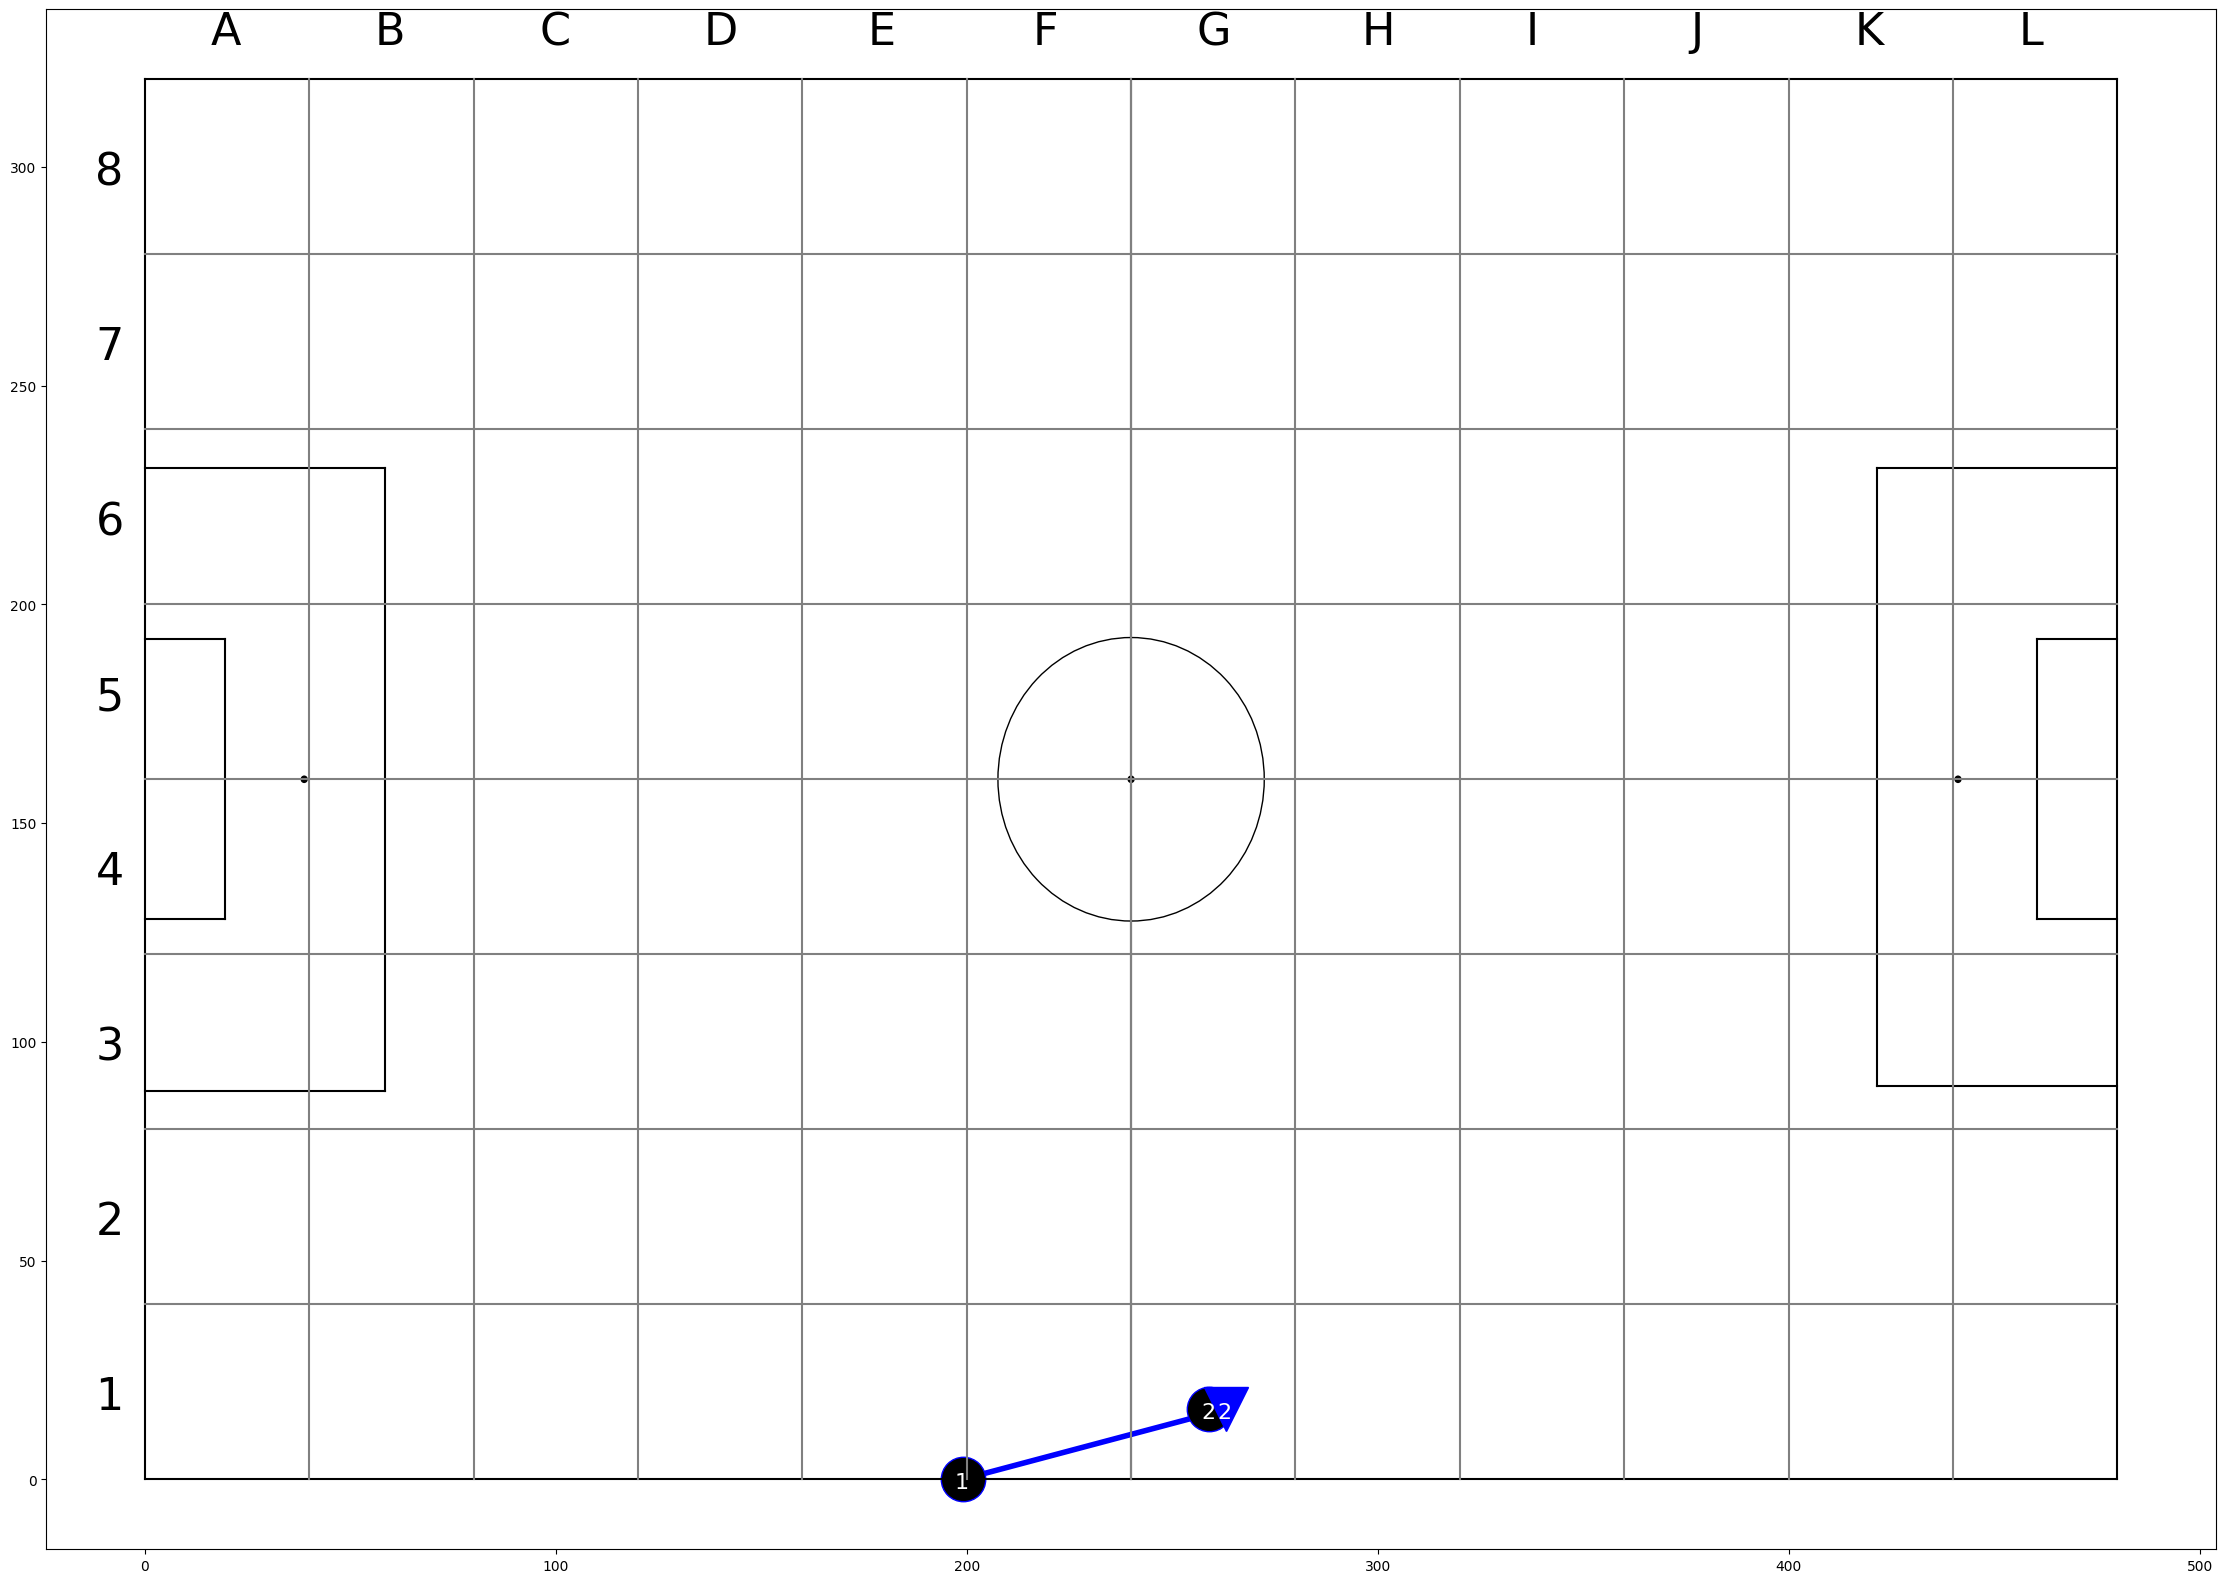

Sequence: 12
Team: Poland
1: Kamil Glik (Pass) <00:05:12.389>
2: Jan Bednarek (Ball Receipt*) <00:05:14.149>
2: Jan Bednarek (Pass) <00:05:14.172>
3: Mateusz Andrzej Klich (Ball Receipt*) <00:05:14.736>
4: Kristoffer Olsson (Interception) <00:05:14.736>
5: Grzegorz Krychowiak (Pass) <00:05:15.315>
6: Albin Ekdal (Pass) <00:05:16.378>
7: Robin Quaison (Ball Receipt*) <00:05:19.207>
8: Jan Bednarek (Pass) <00:05:19.207>
9: Grzegorz Krychowiak (Ball Receipt*) <00:05:20.278>
9: Grzegorz Krychowiak (Pass) <00:05:20.278>
10: Mateusz Andrzej Klich (Ball Receipt*) <00:05:22.914>
10: Mateusz Andrzej Klich (Carry) <00:05:22.914>
10: Mateusz Andrzej Klich (Pass) <00:05:24.673>
11: Grzegorz Krychowiak (Ball Receipt*) <00:05:25.220>
11: Grzegorz Krychowiak (Carry) <00:05:25.220>
11: Grzegorz Krychowiak (Pass) <00:05:26.948>
12: Bartosz Bereszyński (Ball Receipt*) <00:05:27.918>
12: Bartosz Bereszyński (Carry) <00:05:27.918>
12: Bartosz Bereszyński (Pass) <00:05:29.227>
13: Karol Świderski (Ball Rec

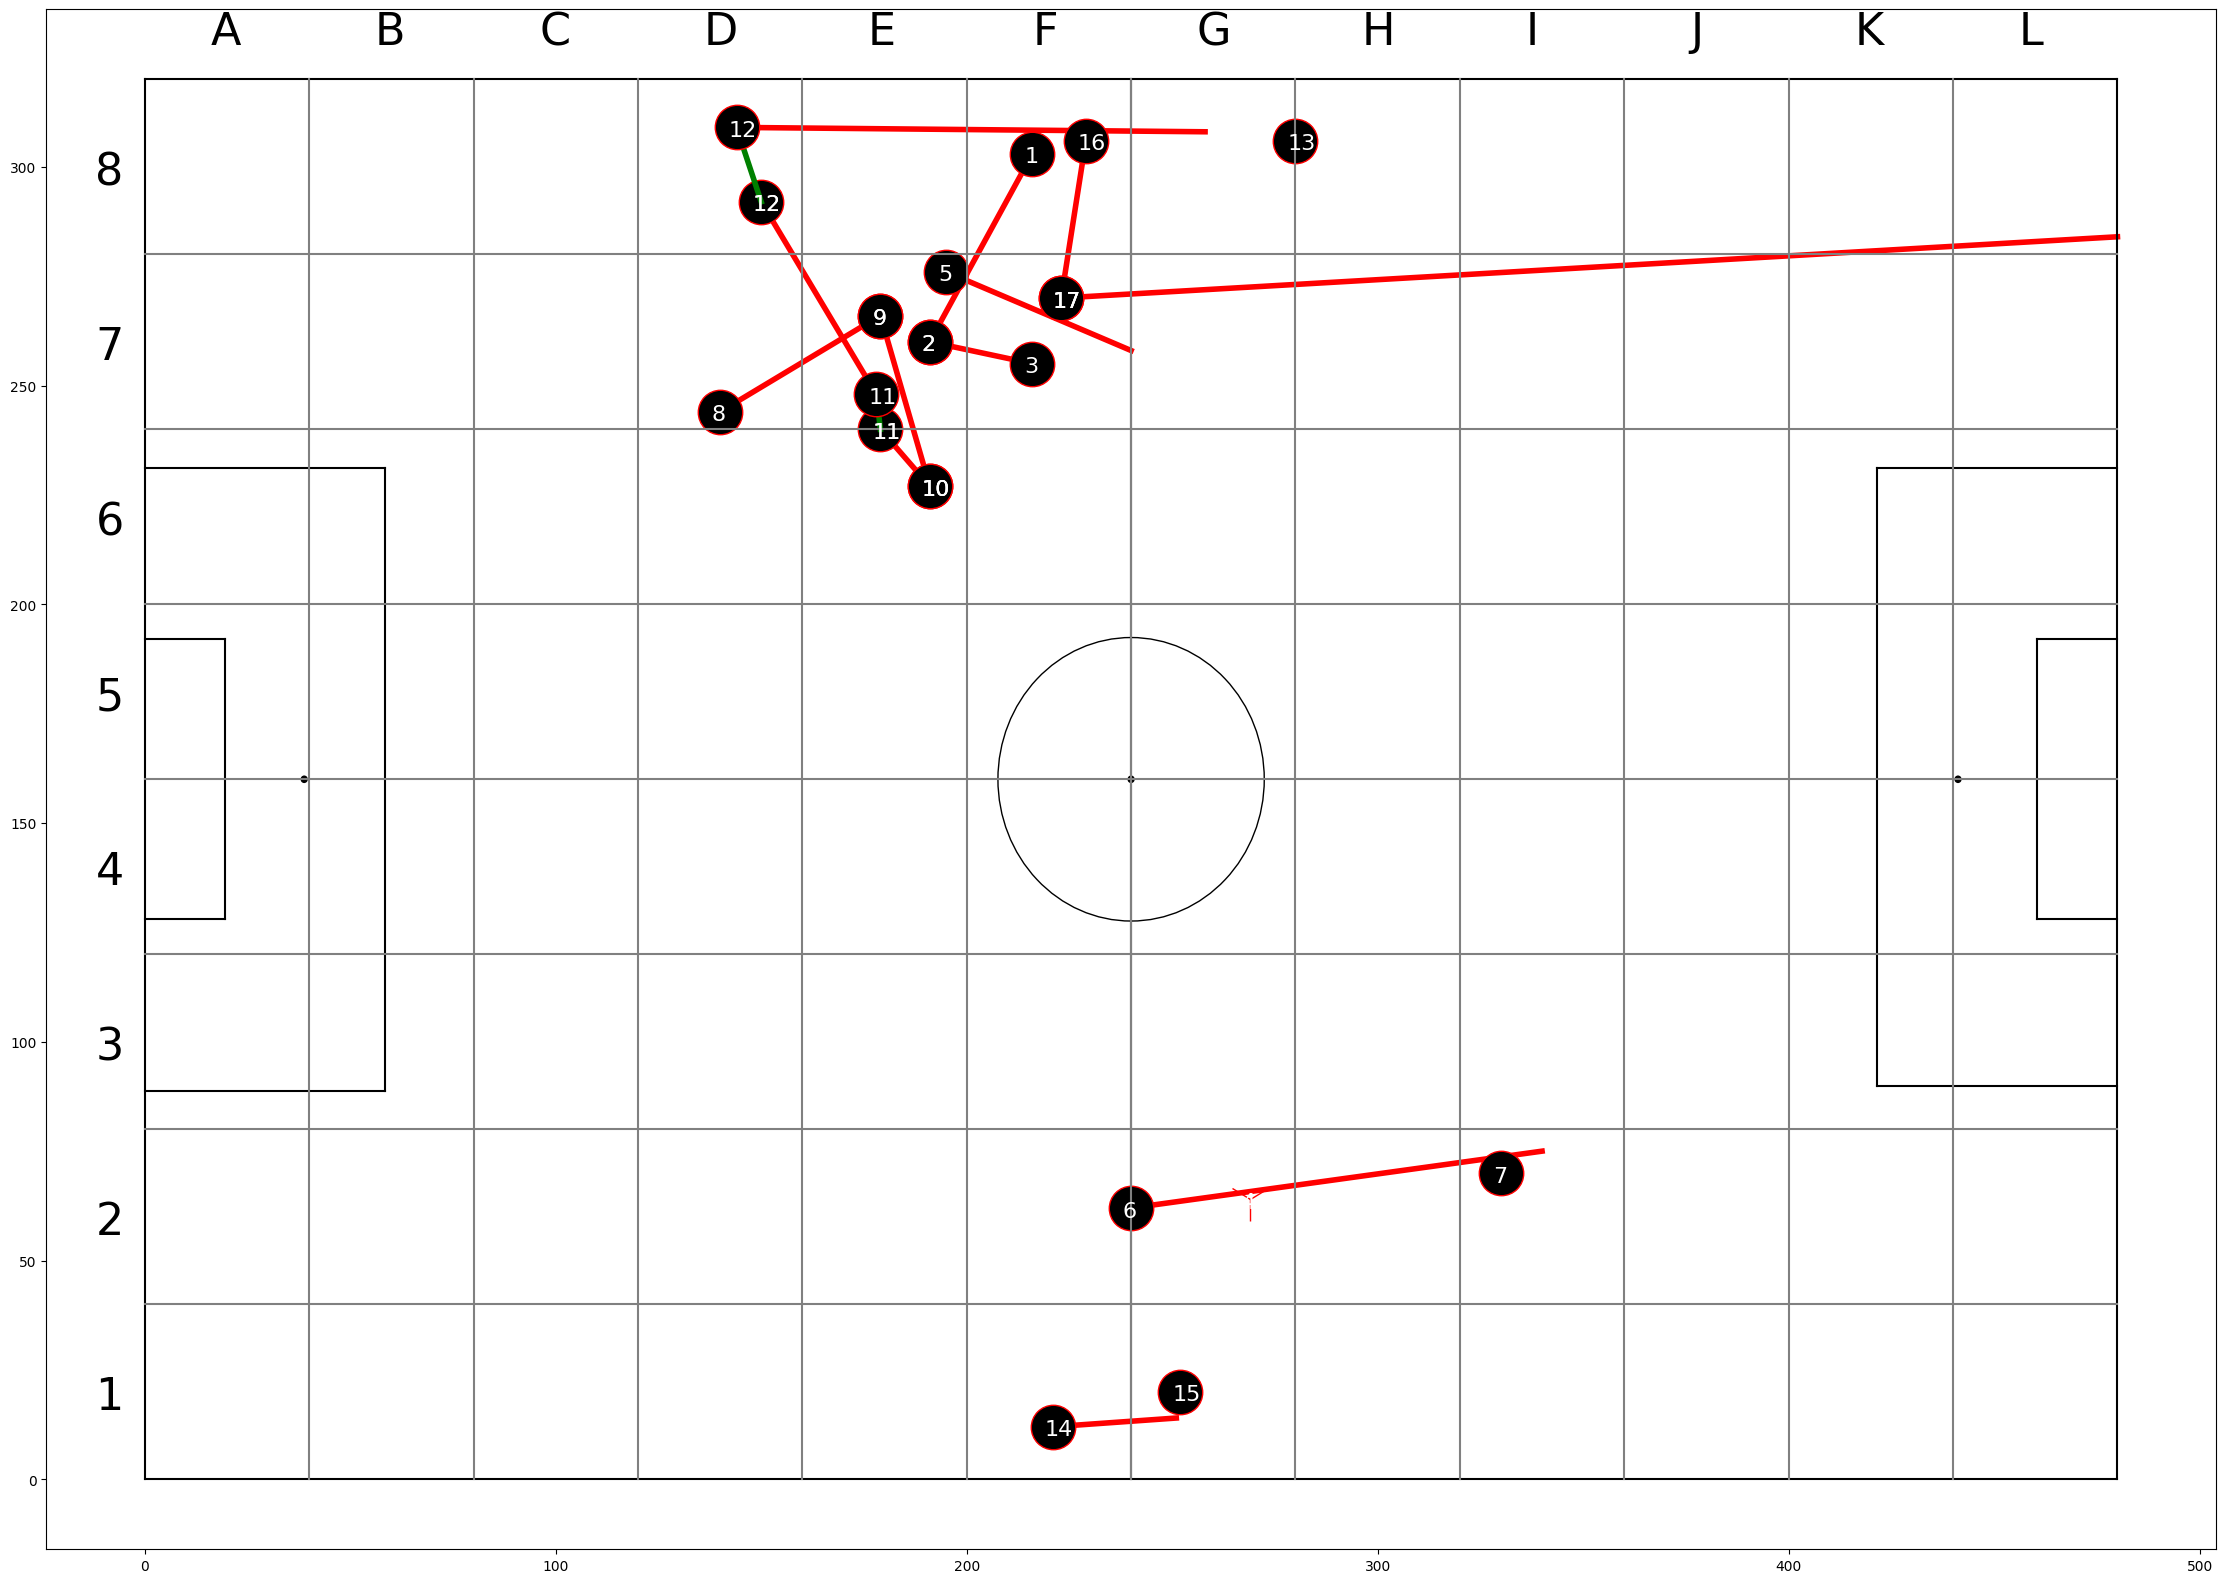

Sequence: 13
Team: Sweden
1: Robin Olsen (Pass) <00:06:07.179>
2: Sebastian Larsson (Ball Receipt*) <00:06:11.801>
2: Sebastian Larsson (Pass) <00:06:11.840>
3: Tymoteusz Puchacz (Duel) <00:06:11.840>
4: Alexander Isak (Ball Receipt*) <00:06:13.887>
5: Jan Bednarek (Interception) <00:06:13.887>
6: Victor Nilsson Lindelöf (Pass) <00:06:47.600>
7: Mikael Lustig (Ball Receipt*) <00:06:49.456>
8: Karol Świderski (Duel) <00:06:49.456>
9: Mikael Lustig (Miscontrol) <00:06:49.456>
10: Alexander Isak (Ball Recovery) <00:06:51.388>
10: Alexander Isak (Carry) <00:06:51.388>
10: Alexander Isak (Dispossessed) <00:06:52.477>
11: Grzegorz Krychowiak (Duel) <00:06:52.477>
12: Alexander Isak (Ball Recovery) <00:06:53.150>
12: Alexander Isak (Carry) <00:06:53.150>
12: Alexander Isak (Dribble) <00:06:53.444>
12: Alexander Isak (Carry) <00:06:53.444>
12: Alexander Isak (Miscontrol) <00:06:53.531>
13: Grzegorz Krychowiak (Ball Recovery) <00:06:53.757>
14: Kristoffer Olsson (Pass) <00:06:54.935>
15: Albin 

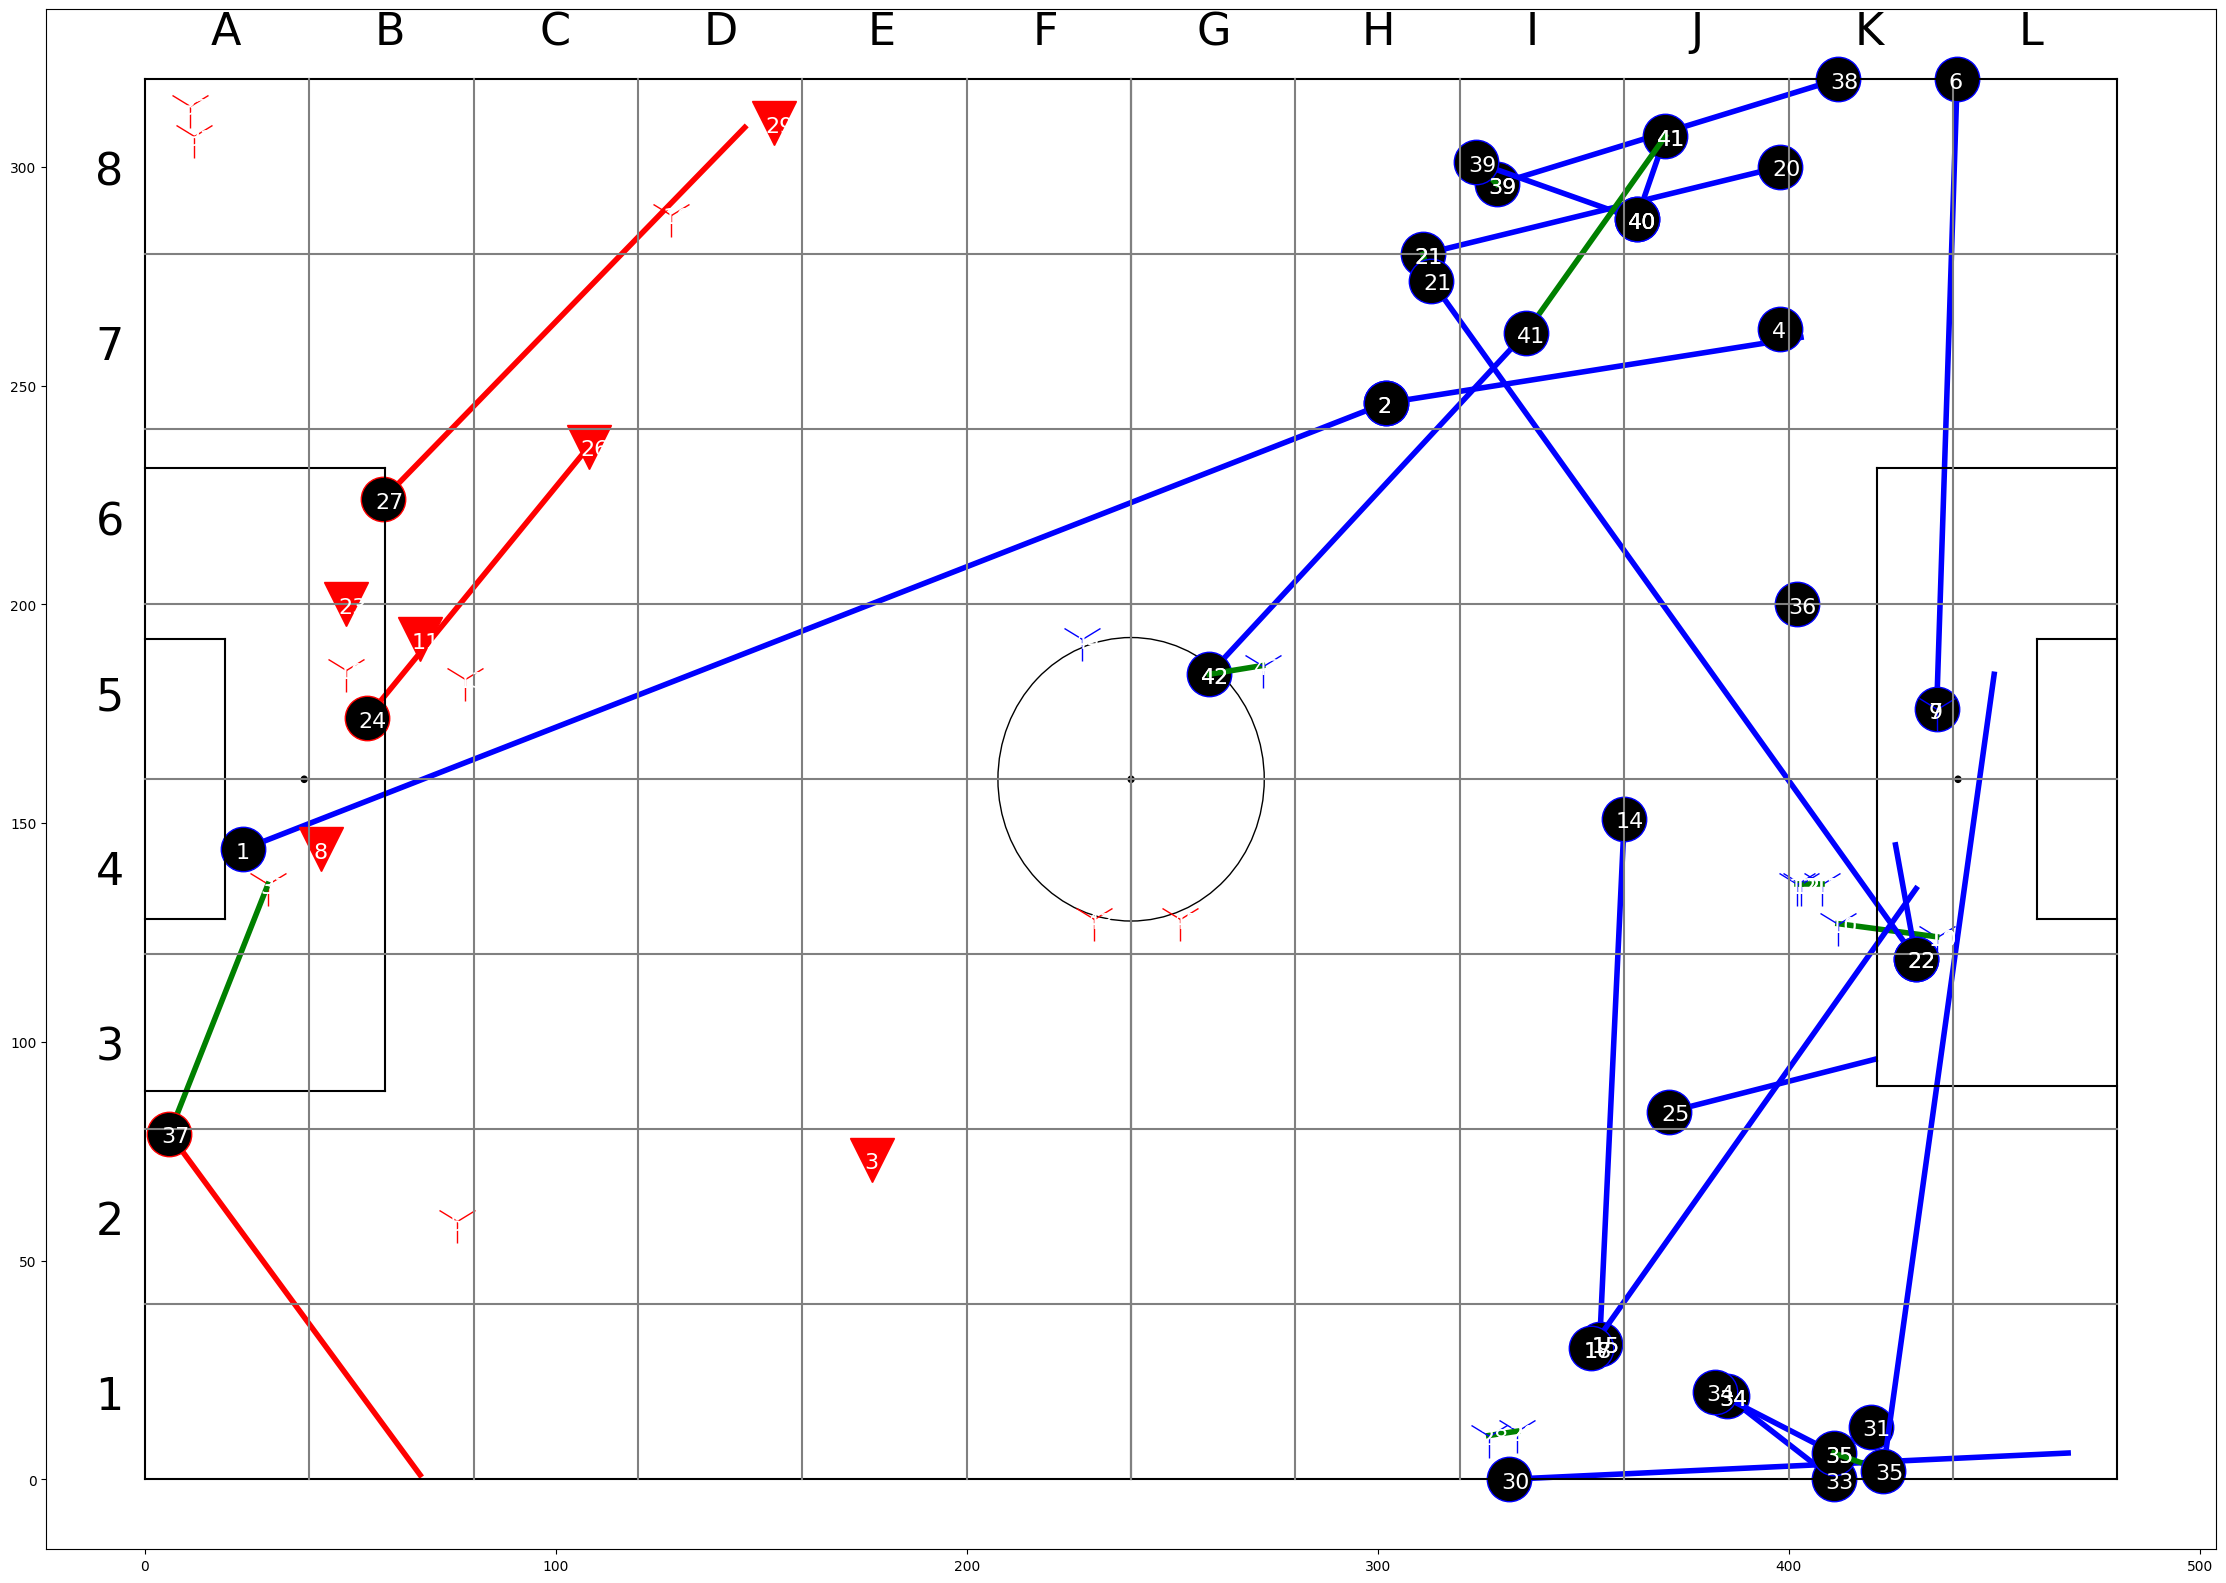

Sequence: 14
Team: Poland
1: Robert Lewandowski (Ball Recovery) <00:09:02.735>
1: Robert Lewandowski (Carry) <00:09:02.735>
1: Robert Lewandowski (Pass) <00:09:06.887>
2: Piotr Zieliński (Ball Receipt*) <00:09:11.706>
2: Piotr Zieliński (Carry) <00:09:11.706>
2: Piotr Zieliński (Pass) <00:09:12.182>
3: Tymoteusz Puchacz (Ball Receipt*) <00:09:14.179>
3: Tymoteusz Puchacz (Carry) <00:09:14.179>
3: Tymoteusz Puchacz (Pass) <00:09:16.077>
4: Kristoffer Olsson (Block) <00:09:16.312>
5: Piotr Zieliński (Pass) <00:09:52.918>
6: Kamil Jóźwiak (Duel) <00:09:54.294>
7: Marcus Andreas Danielsson (Clearance) <00:09:54.294>
8: Kamil Glik (Foul Committed) <00:09:56.373>
9: Albin Ekdal (Foul Won) <00:09:56.373>


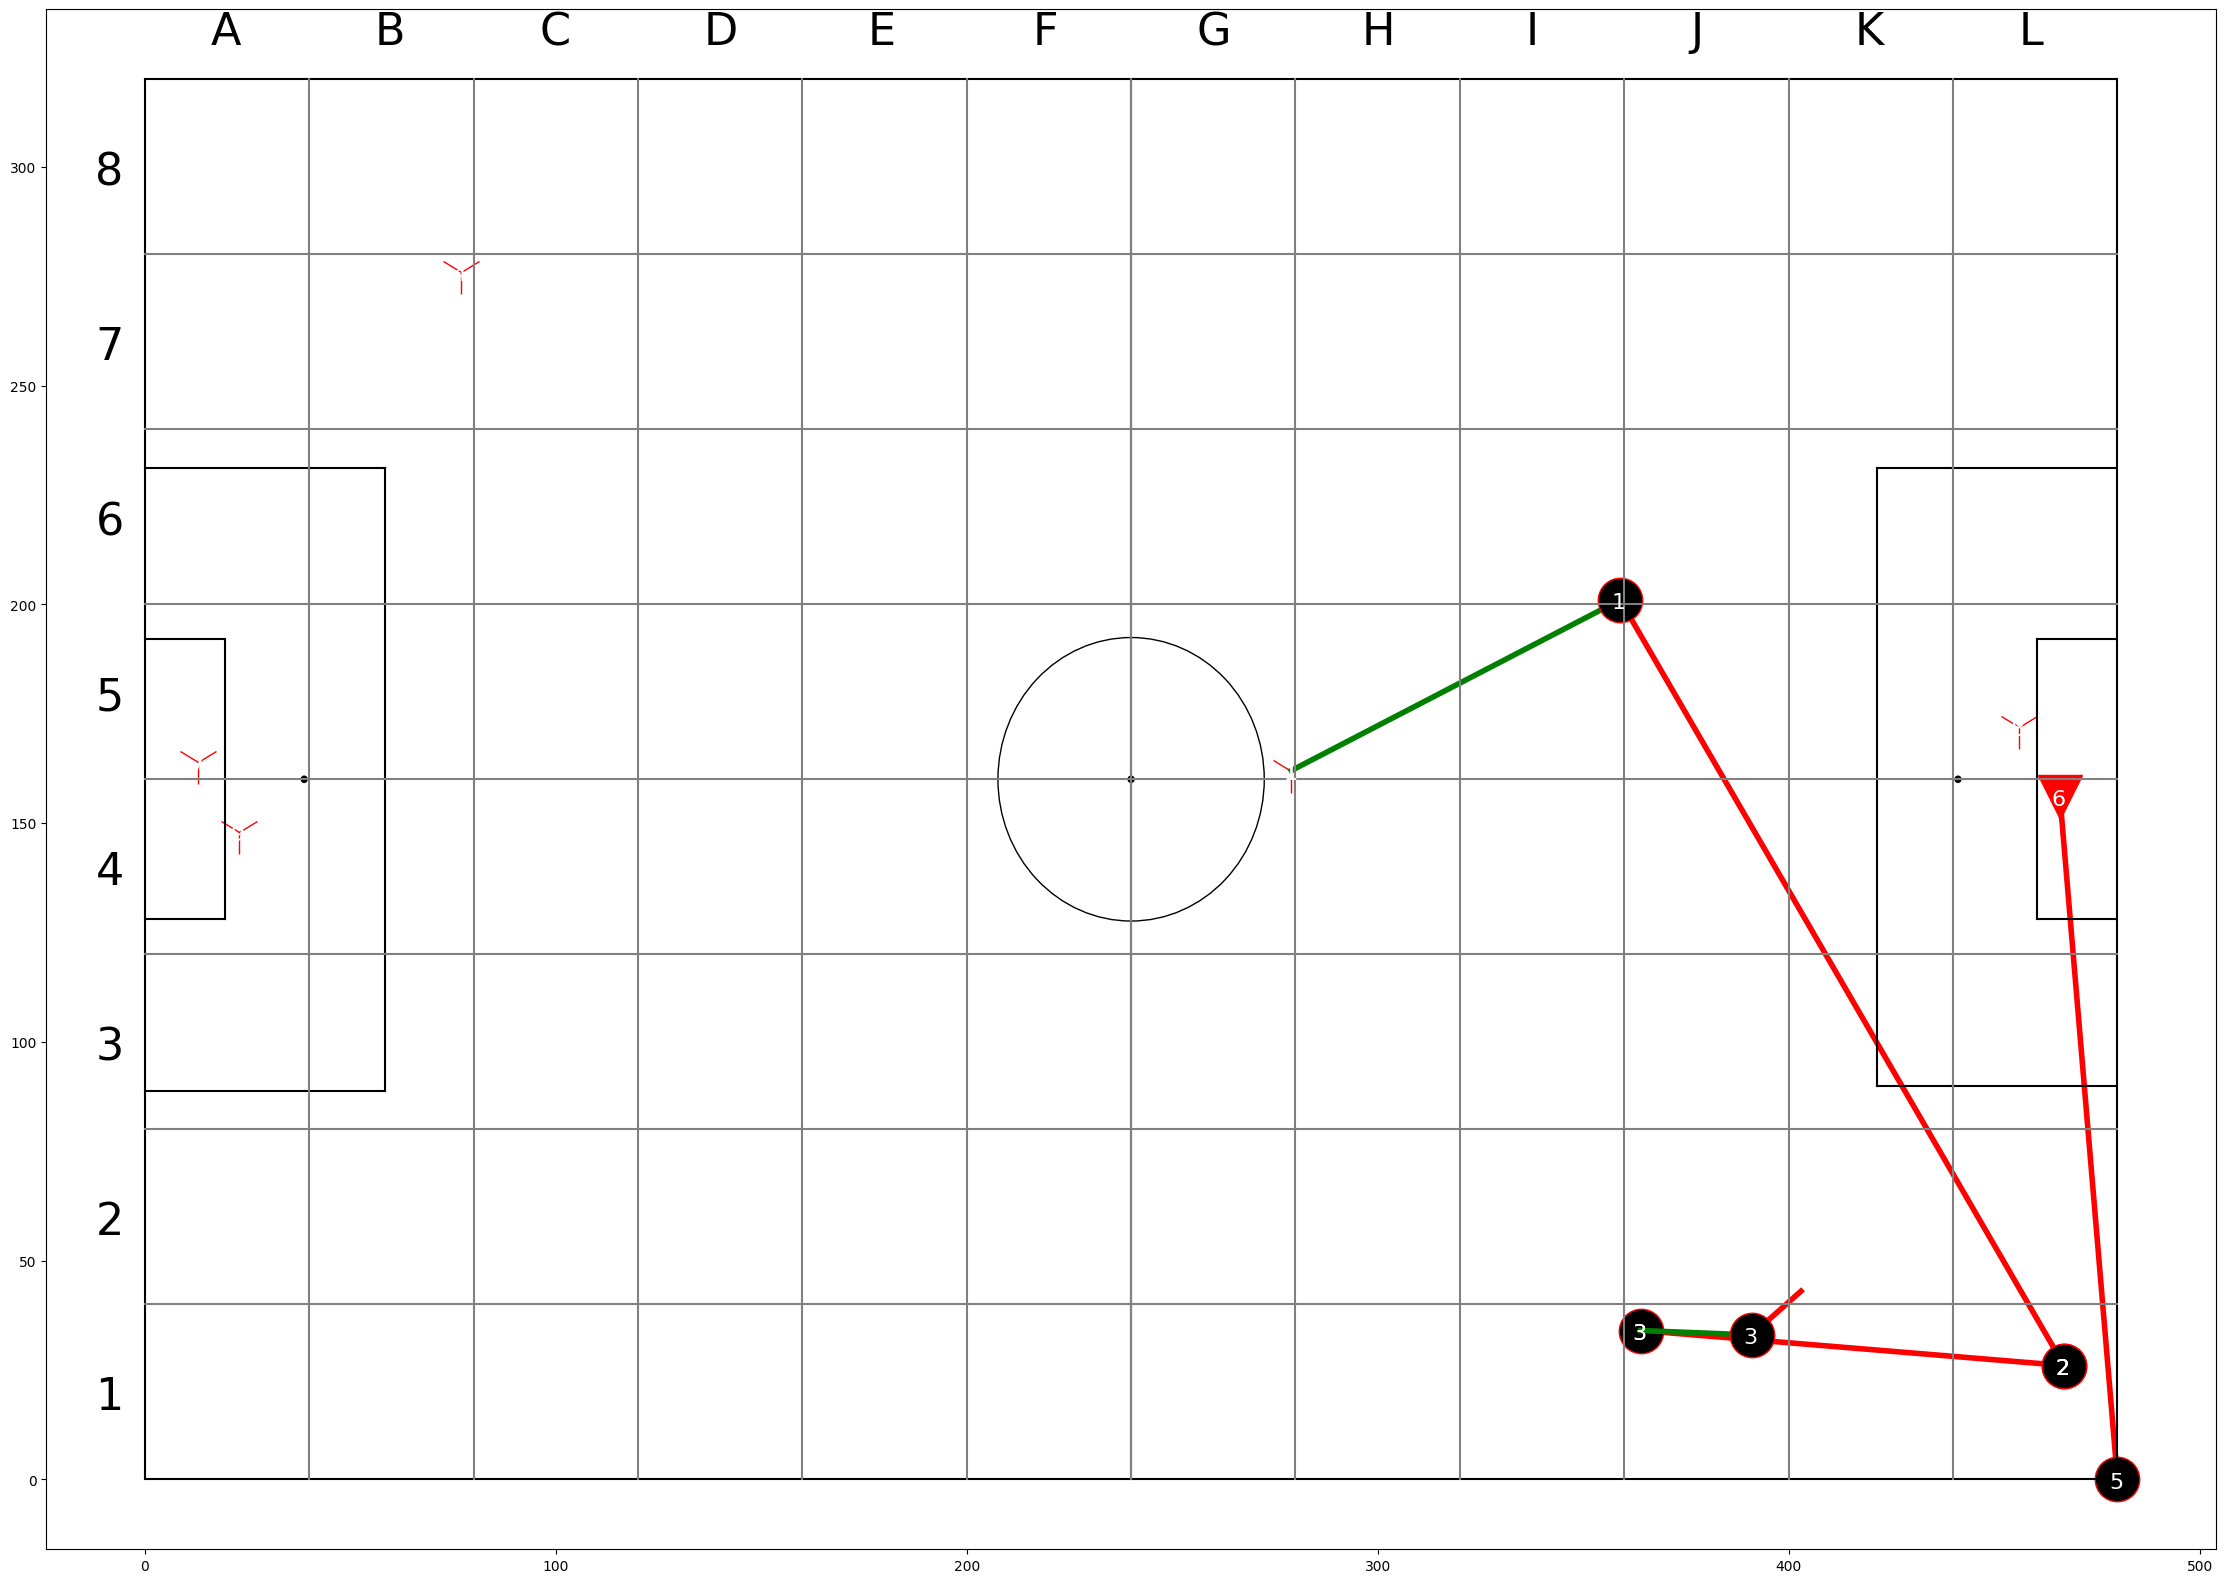

Sequence: 15
Team: Sweden
1: Robin Olsen (Pass) <00:10:30.272>
2: Mikael Lustig (Ball Receipt*) <00:10:33.859>
2: Mikael Lustig (Duel) <00:10:33.859>
3: Tymoteusz Puchacz (Clearance) <00:10:33.859>
3: Tymoteusz Puchacz (Block) <00:10:33.939>
4: Kristoffer Olsson (Pass) <00:10:35.560>
5: Mikael Lustig (Ball Receipt*) <00:10:36.630>
5: Mikael Lustig (Carry) <00:10:36.630>
5: Mikael Lustig (Pass) <00:10:38.425>
6: Emil Peter Forsberg (Ball Receipt*) <00:10:39.808>
6: Emil Peter Forsberg (Miscontrol) <00:10:39.808>


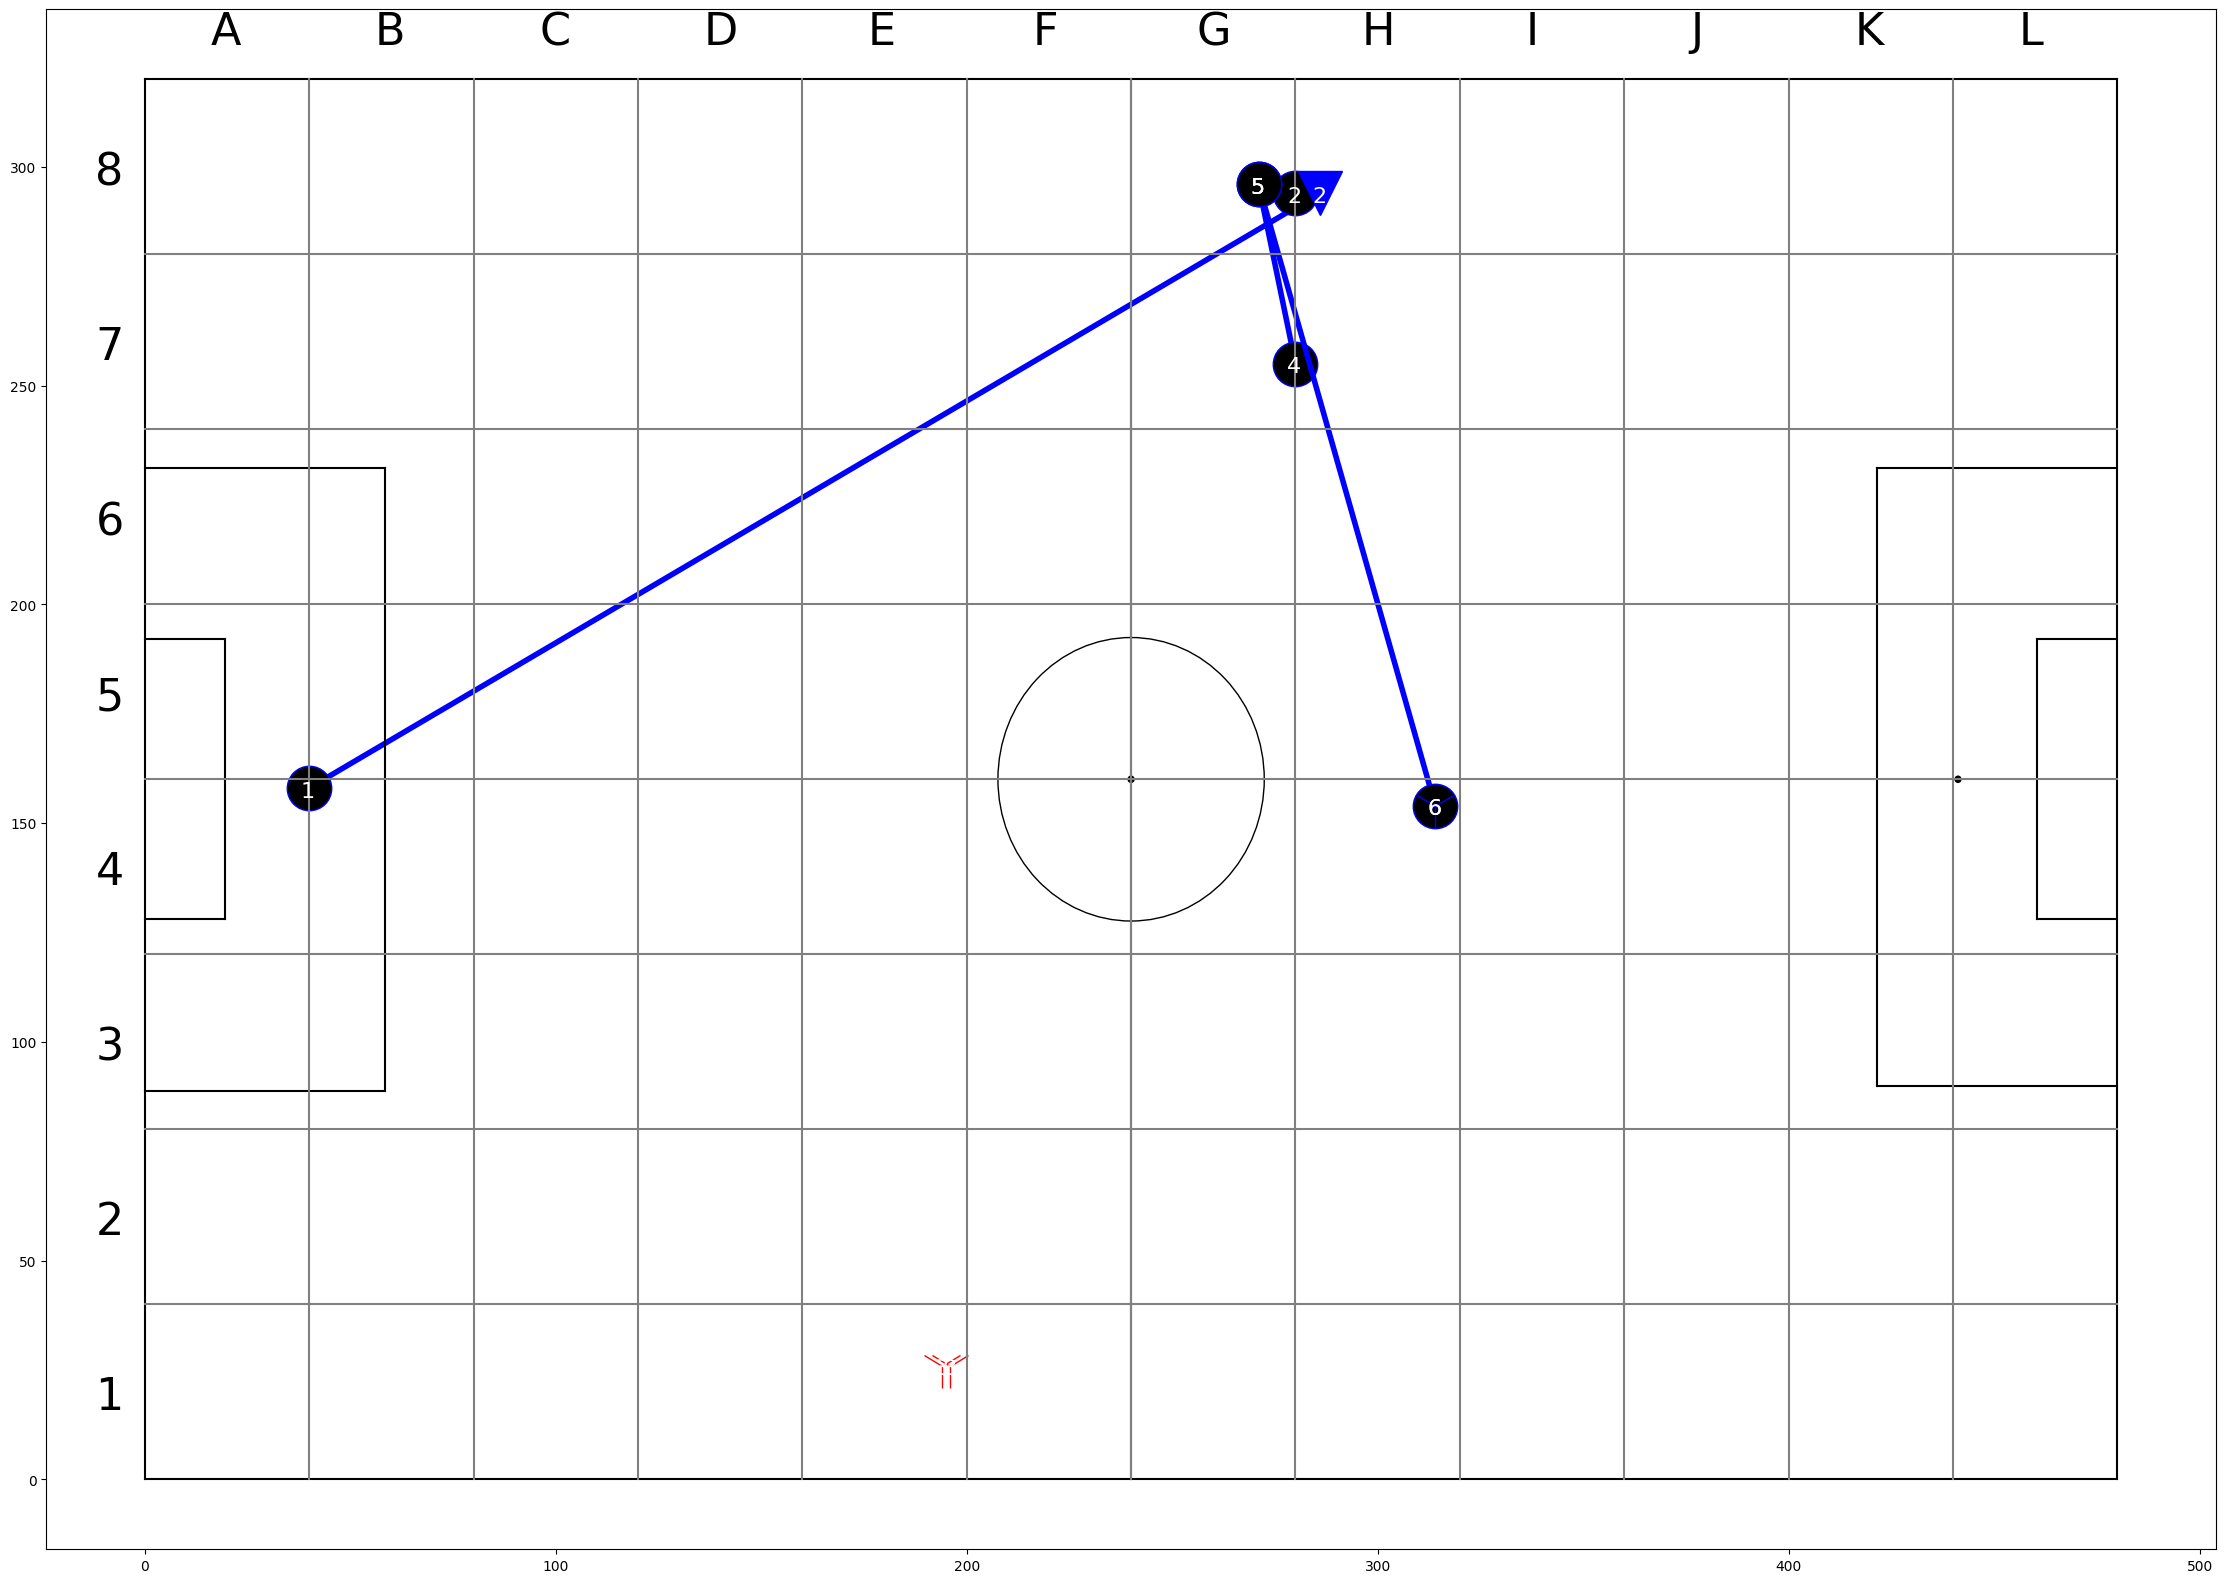

Sequence: 16
Team: Poland
1: Kamil Jóźwiak (Ball Recovery) <00:10:42.118>
1: Kamil Jóźwiak (Carry) <00:10:42.118>
1: Kamil Jóźwiak (Pass) <00:10:50.369>
2: Bartosz Bereszyński (Ball Receipt*) <00:10:51.590>
2: Bartosz Bereszyński (Carry) <00:10:51.590>
2: Bartosz Bereszyński (Pass) <00:10:52.977>
3: Kamil Glik (Ball Receipt*) <00:10:54.537>
3: Kamil Glik (Carry) <00:10:54.537>
3: Kamil Glik (Pass) <00:10:55.344>
4: Jan Bednarek (Ball Receipt*) <00:10:56.723>
4: Jan Bednarek (Carry) <00:10:56.723>
4: Jan Bednarek (Pass) <00:11:00.859>
5: Kamil Glik (Ball Receipt*) <00:11:02.511>
5: Kamil Glik (Carry) <00:11:02.511>
5: Kamil Glik (Pass) <00:11:03.540>
6: Bartosz Bereszyński (Ball Receipt*) <00:11:04.755>
6: Bartosz Bereszyński (Carry) <00:11:04.755>
6: Bartosz Bereszyński (Pass) <00:11:05.687>
7: Kamil Jóźwiak (Ball Receipt*) <00:11:07.024>
7: Kamil Jóźwiak (Carry) <00:11:07.024>
7: Kamil Jóźwiak (Pass) <00:11:09.406>
8: Piotr Zieliński (Ball Receipt*) <00:11:10.434>
8: Piotr Zieliński (

ValueError: invalid literal for int() with base 10: ''

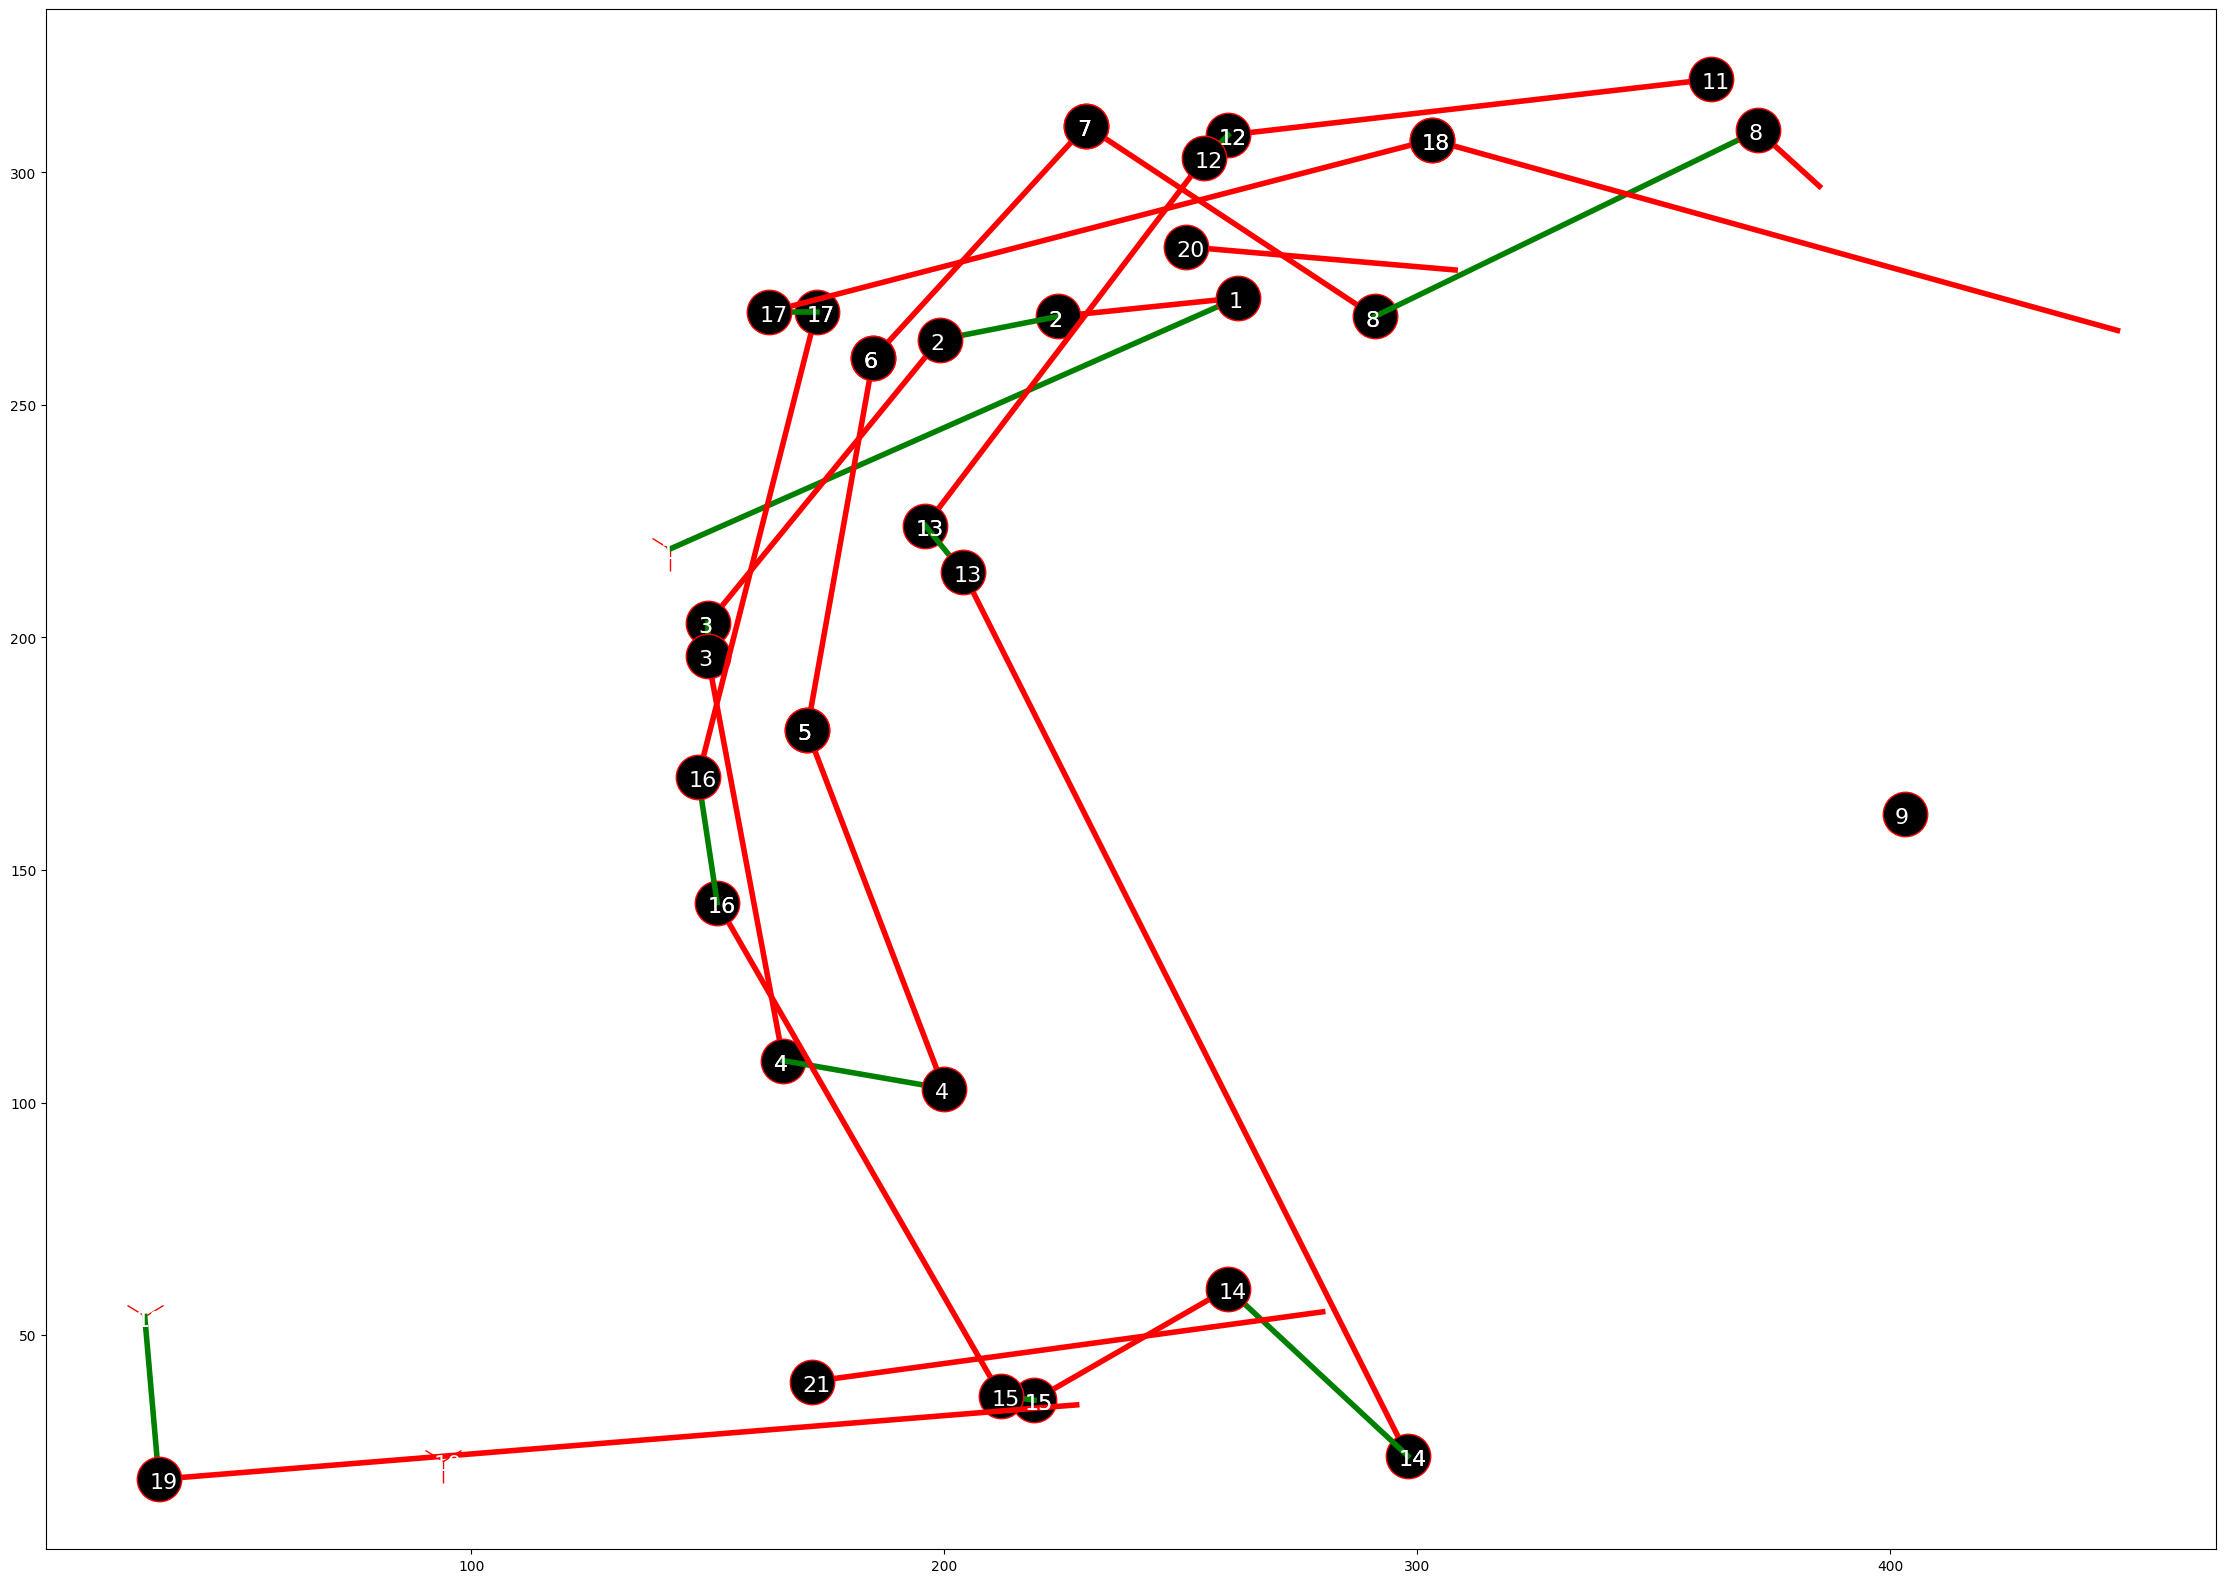

In [15]:
start_team = merged_events['possession_team'][0]

for i, s in enumerate(sequences):
    print(f'Sequence: {i+1}')
    draw_events_sequence2(s, start_team, 12, 8, scale=4)
    if i == 15:
        break